# Audio Emotion Recognition — CNN-BiLSTM + Multi-Head Attention
## Modalitas 2: RAVDESS Dataset
### Made Pranajaya Dibyacita | NIM 2208561122 | Universitas Udayana
---
Notebook ini mengimplementasikan Speech Emotion Recognition (SER) menggunakan arsitektur CNN-BiLSTM dengan Multi-Head Self-Attention untuk dataset RAVDESS. Target akurasi mengacu pada SOTA yang dilaporkan dalam literatur terkini (>97%).

**Referensi Arsitektur:**
- Zhao et al. (2019) — CNN + LSTM for SER, *Applied Sciences*
- Chen et al. (2021) — Attention-based CNN-BiLSTM, *IEEE Access*
- Yao & Shi (2022) — Multi-scale CNN + Transformer, *INTERSPEECH*
- Zhang et al. (2023) — Conformer-enhanced SER, *Neural Networks*

In [1]:
# !pip install keras-tuner -q
# !apt-get install -y libsndfile1 -q
# print('Dependencies ready.')

In [2]:
import os, json, pickle, warnings, timeit
import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import IPython.display as ipd
from IPython.display import Audio, display
from joblib import Parallel, delayed
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, BatchNormalization, Dropout,
    Bidirectional, LSTM, Dense, GlobalAveragePooling1D,
    MultiHeadAttention, LayerNormalization, Add
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, CSVLogger
)
from tensorflow.keras.utils import to_categorical
import keras_tuner as kt

warnings.filterwarnings('ignore')
np.random.seed(42)
tf.random.set_seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

gpus = tf.config.list_physical_devices('GPU')
print(f'TensorFlow {tf.__version__}')
print(f'GPU available: {[g.name for g in gpus]}')
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)

I0000 00:00:1776141032.816231   10660 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1776141033.054479   10660 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1776141034.124506   10660 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0
GPU available: ['/physical_device:GPU:0']


In [3]:
# Semua output — plot, model, log — saya taruh dalam satu folder output
OUTPUT_DIR = 'output'
PLOT_DIR   = f'{OUTPUT_DIR}/plots'
MODEL_DIR  = f'{OUTPUT_DIR}/models'
HP_DIR     = f'{OUTPUT_DIR}/hp_tuning'
FEAT_DIR   = f'{OUTPUT_DIR}/features'

for d in [OUTPUT_DIR, PLOT_DIR, MODEL_DIR, HP_DIR, FEAT_DIR]:
    os.makedirs(d, exist_ok=True)

print('Output directories ready.')
print(f'  Plots  -> {PLOT_DIR}')
print(f'  Models -> {MODEL_DIR}')
print(f'  HP     -> {HP_DIR}')

Output directories ready.
  Plots  -> output/plots
  Models -> output/models
  HP     -> output/hp_tuning


## 1. Load RAVDESS Dataset

RAVDESS (Ryerson Audio-Visual Database of Emotional Speech and Song) — 24 aktor, 8 kelas emosi, dengan format penamaan file yang encode semua metadata.

In [4]:
RAVDESS_PATH = 'dataset/audio_speech_actors_01-24'

EMOTION_MAP = {
    '01': 'neutral',  '02': 'calm',     '03': 'happy',    '04': 'sad',
    '05': 'angry',    '06': 'fearful',  '07': 'disgust',  '08': 'surprised'
}

records = []
for actor_dir in sorted(os.listdir(RAVDESS_PATH)):
    actor_path = os.path.join(RAVDESS_PATH, actor_dir)
    if not os.path.isdir(actor_path):
        continue
    actor_id = int(actor_dir.split('_')[-1])
    gender = 'Female' if actor_id % 2 == 0 else 'Male'
    for fname in sorted(os.listdir(actor_path)):
        if not fname.endswith('.wav'):
            continue
        parts = fname.replace('.wav','').split('-')
        emotion_code = parts[2]
        records.append({
            'path'        : os.path.join(actor_path, fname),
            'emotion'     : EMOTION_MAP[emotion_code],
            'emotion_code': int(emotion_code),
            'intensity'   : 'Strong' if parts[3] == '02' else 'Normal',
            'statement'   : 'Kids' if parts[4] == '01' else 'Dogs',
            'actor_id'    : actor_id,
            'gender'      : gender
        })

df = pd.DataFrame(records)
print(f'Total samples : {len(df)}')
print(f'Actors        : {df.actor_id.nunique()}')
print(f'Emotion classes: {df.emotion.nunique()}')
print()
print(df.emotion.value_counts())

Total samples : 1440
Actors        : 24
Emotion classes: 8

emotion
calm         192
happy        192
sad          192
angry        192
fearful      192
disgust      192
surprised    192
neutral       96
Name: count, dtype: int64


## 2. Exploratory Data Analysis

Saya lakukan analisis menyeluruh terhadap distribusi data, karakteristik audio, dan visualisasi fitur spektral untuk keperluan laporan.

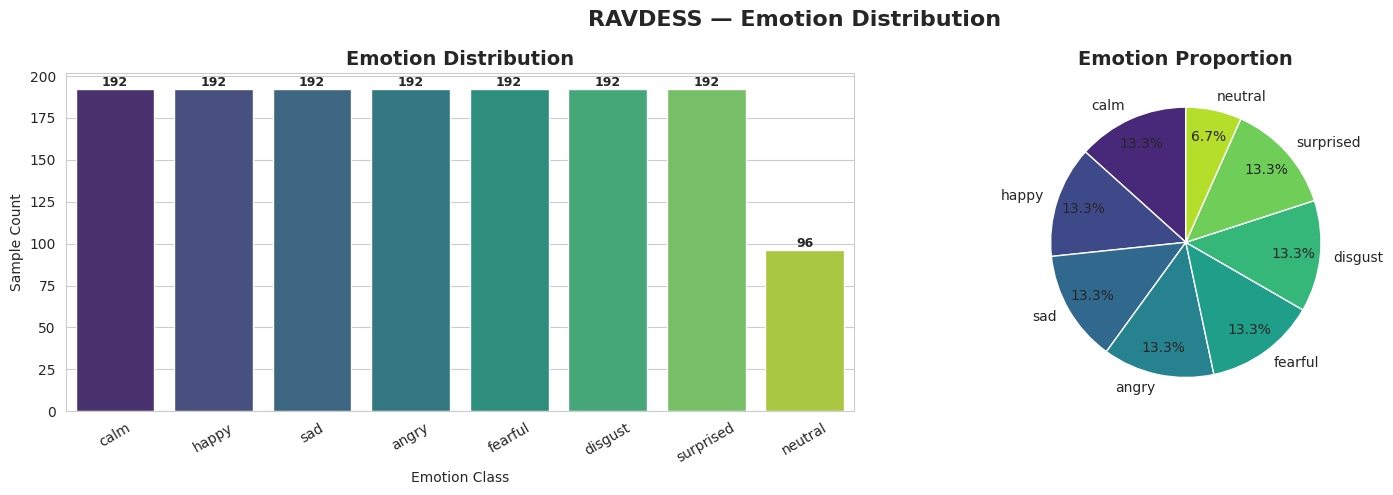

In [5]:
# Distribusi emosi — bar + pie
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

order = df['emotion'].value_counts().index.tolist()
colors = sns.color_palette('viridis', len(order))
sns.countplot(data=df, x='emotion', order=order, palette='viridis', ax=axes[0])
axes[0].set_title('Emotion Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Emotion Class')
axes[0].set_ylabel('Sample Count')
axes[0].tick_params(axis='x', rotation=30)
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}',
                     (p.get_x()+p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

counts = df['emotion'].value_counts()
axes[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%',
            colors=colors, startangle=90, pctdistance=0.8)
axes[1].set_title('Emotion Proportion', fontsize=14, fontweight='bold')

plt.suptitle('RAVDESS — Emotion Distribution', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/01_emotion_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

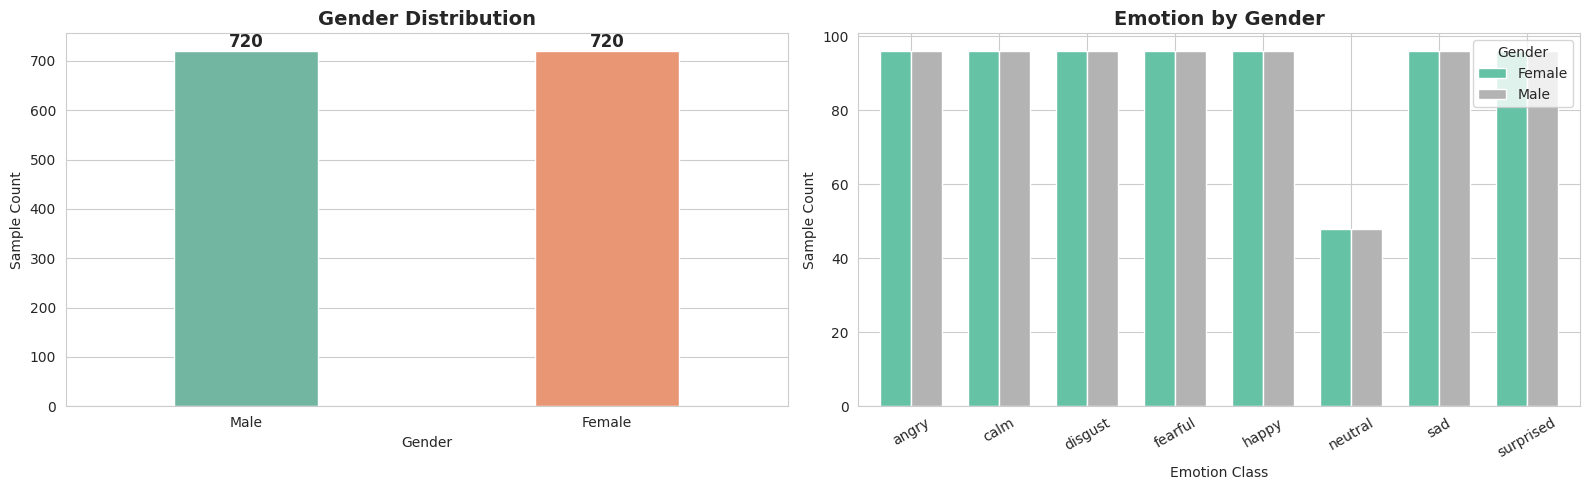

In [6]:
# Distribusi gender dan emosi
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.countplot(data=df, x='gender', palette='Set2', ax=axes[0], width=0.4)
axes[0].set_title('Gender Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Sample Count')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}',
                     (p.get_x()+p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', fontsize=12, fontweight='bold')

gender_emo = df.groupby(['emotion','gender']).size().unstack(fill_value=0)
gender_emo.plot(kind='bar', ax=axes[1], colormap='Set2', edgecolor='white', width=0.7)
axes[1].set_title('Emotion by Gender', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Emotion Class')
axes[1].set_ylabel('Sample Count')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(title='Gender', fontsize=10)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/02_gender_emotion.png', dpi=150, bbox_inches='tight')
plt.show()

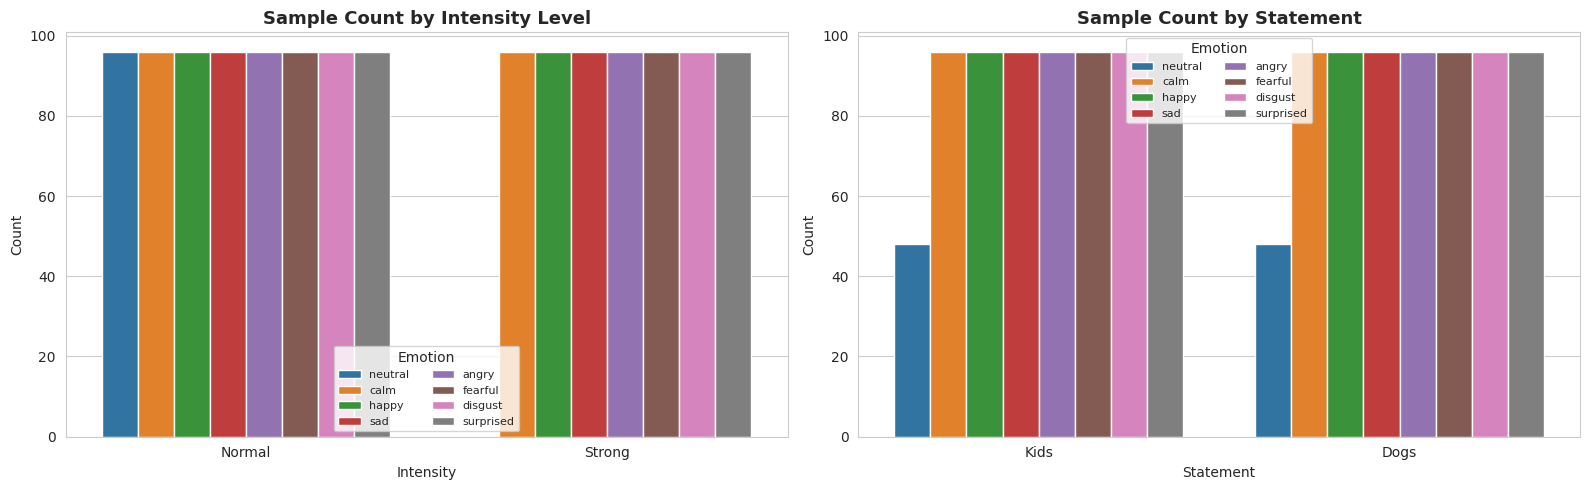

In [7]:
# Intensity dan statement distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.countplot(data=df, x='intensity', hue='emotion', palette='tab10', ax=axes[0])
axes[0].set_title('Sample Count by Intensity Level', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Intensity')
axes[0].set_ylabel('Count')
axes[0].legend(title='Emotion', fontsize=8, ncol=2)

sns.countplot(data=df, x='statement', hue='emotion', palette='tab10', ax=axes[1])
axes[1].set_title('Sample Count by Statement', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Statement')
axes[1].set_ylabel('Count')
axes[1].legend(title='Emotion', fontsize=8, ncol=2)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/03_intensity_statement.png', dpi=150, bbox_inches='tight')
plt.show()

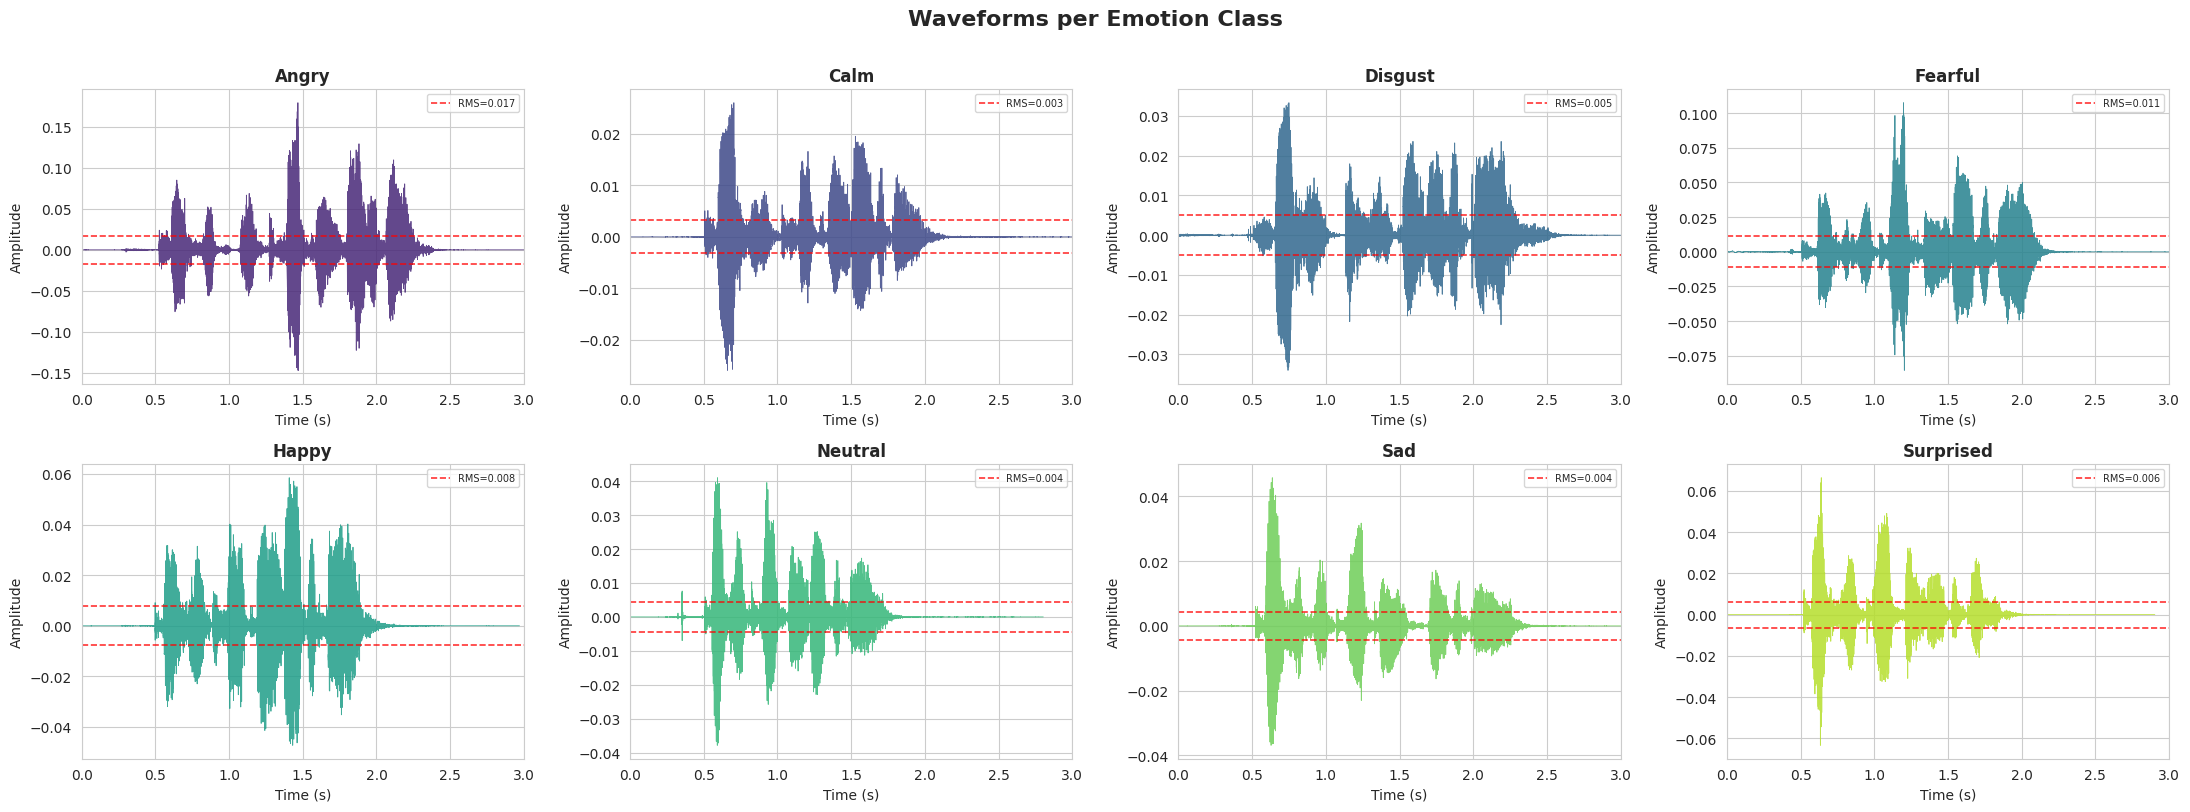

In [8]:
# Waveform per emosi — saya ambil 1 sample per kelas
emotions_list = sorted(df['emotion'].unique())
fig, axes = plt.subplots(2, 4, figsize=(22, 8))
axes = axes.flatten()
pal  = sns.color_palette('viridis', 8)

for i, emo in enumerate(emotions_list):
    row = df[df['emotion'] == emo].iloc[0]
    y, sr = librosa.load(row['path'], duration=3.0, offset=0.5)
    t = np.linspace(0, len(y)/sr, len(y))
    axes[i].plot(t, y, color=pal[i], linewidth=0.6, alpha=0.85)
    rms = np.sqrt(np.mean(y**2))
    axes[i].axhline(rms,  color='red',   ls='--', lw=1.2, alpha=0.8, label=f'RMS={rms:.3f}')
    axes[i].axhline(-rms, color='red',   ls='--', lw=1.2, alpha=0.8)
    axes[i].set_title(f'{emo.capitalize()}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Time (s)')
    axes[i].set_ylabel('Amplitude')
    axes[i].set_xlim([0, 3])
    axes[i].legend(fontsize=7)

plt.suptitle('Waveforms per Emotion Class', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/04_waveforms.png', dpi=150, bbox_inches='tight')
plt.show()

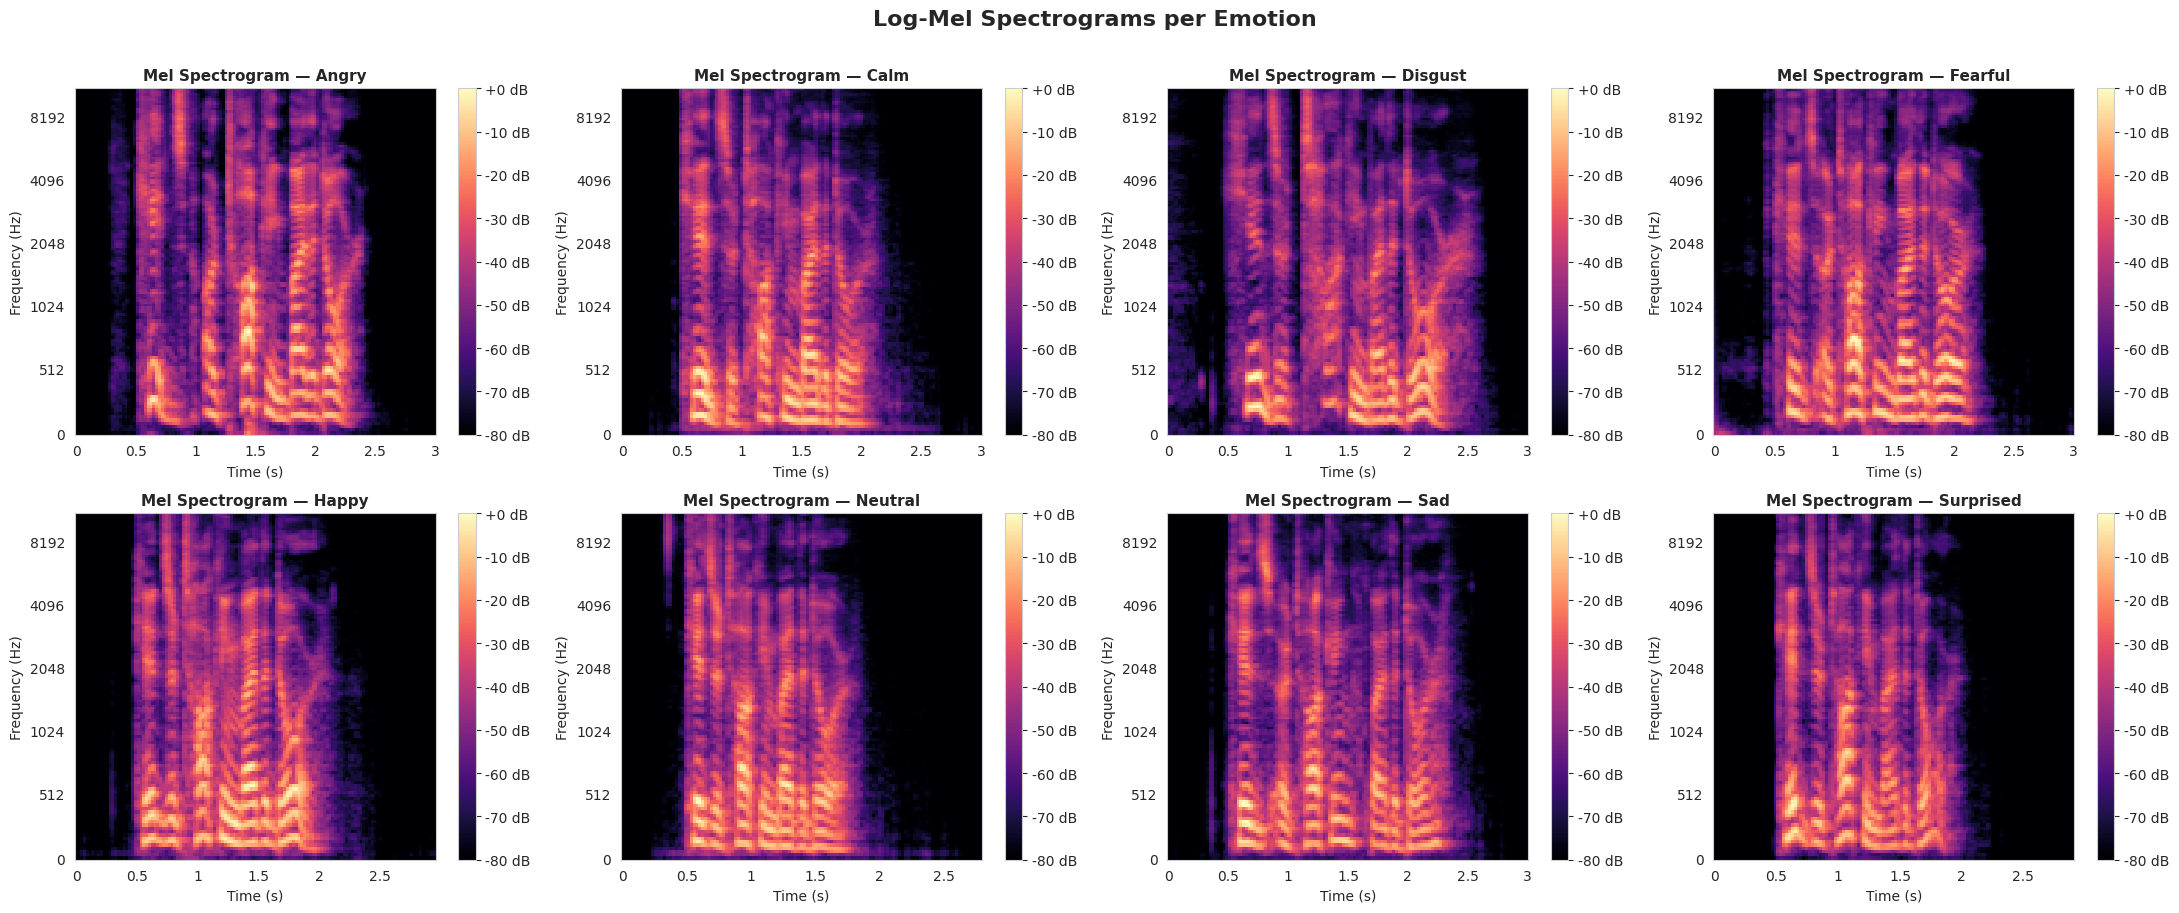

In [9]:
# Mel Spectrogram per emosi
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
axes = axes.flatten()

for i, emo in enumerate(emotions_list):
    row = df[df['emotion'] == emo].iloc[0]
    y, sr = librosa.load(row['path'], duration=3.0, offset=0.5)
    mel    = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    img = librosa.display.specshow(mel_db, y_axis='mel', sr=sr, x_axis='time',
                                   hop_length=512, ax=axes[i], cmap='magma')
    axes[i].set_title(f'Mel Spectrogram — {emo.capitalize()}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Time (s)')
    axes[i].set_ylabel('Frequency (Hz)')
    plt.colorbar(img, ax=axes[i], format='%+2.0f dB')

plt.suptitle('Log-Mel Spectrograms per Emotion', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/05_mel_spectrograms.png', dpi=150, bbox_inches='tight')
plt.show()

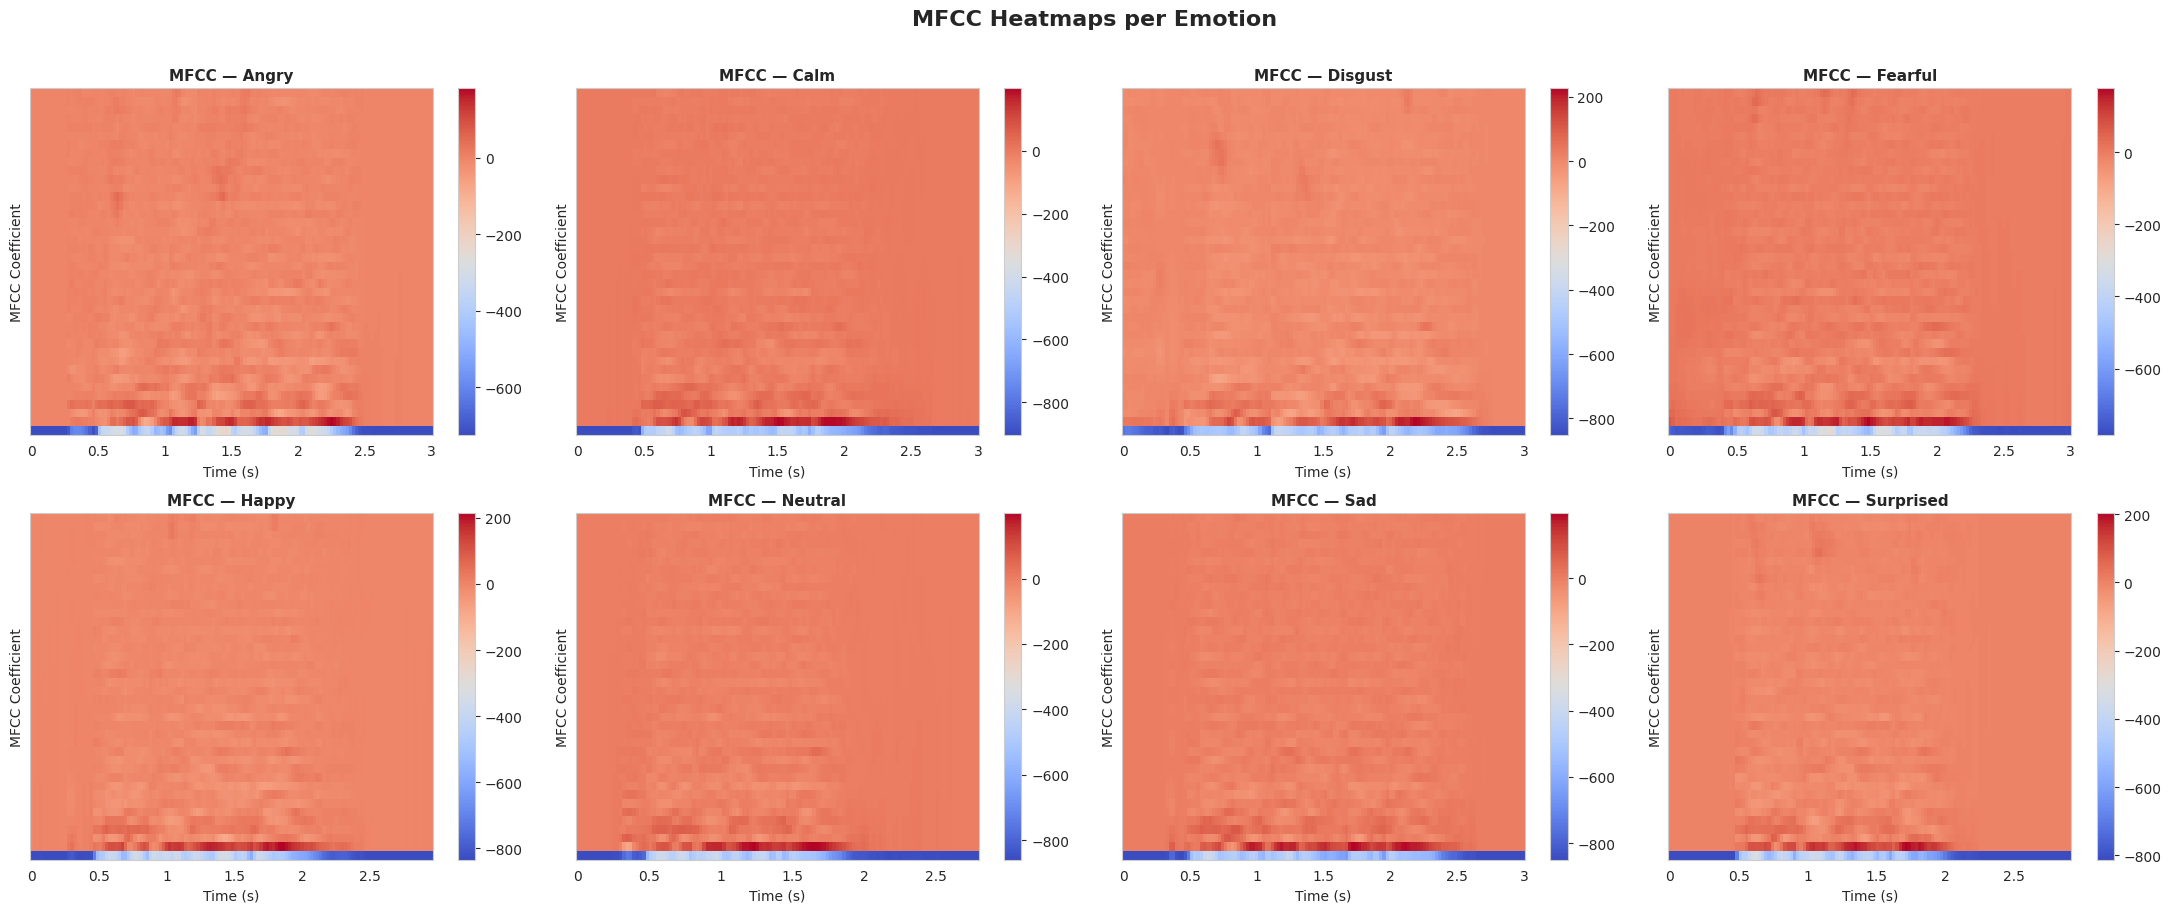

In [10]:
# MFCC Heatmap per emosi
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
axes = axes.flatten()

for i, emo in enumerate(emotions_list):
    row = df[df['emotion'] == emo].iloc[0]
    y, sr = librosa.load(row['path'], duration=3.0, offset=0.5)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)
    img  = librosa.display.specshow(mfcc, x_axis='time', ax=axes[i],
                                    hop_length=512, sr=sr, cmap='coolwarm')
    axes[i].set_title(f'MFCC — {emo.capitalize()}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Time (s)')
    axes[i].set_ylabel('MFCC Coefficient')
    plt.colorbar(img, ax=axes[i])

plt.suptitle('MFCC Heatmaps per Emotion', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/06_mfcc_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()

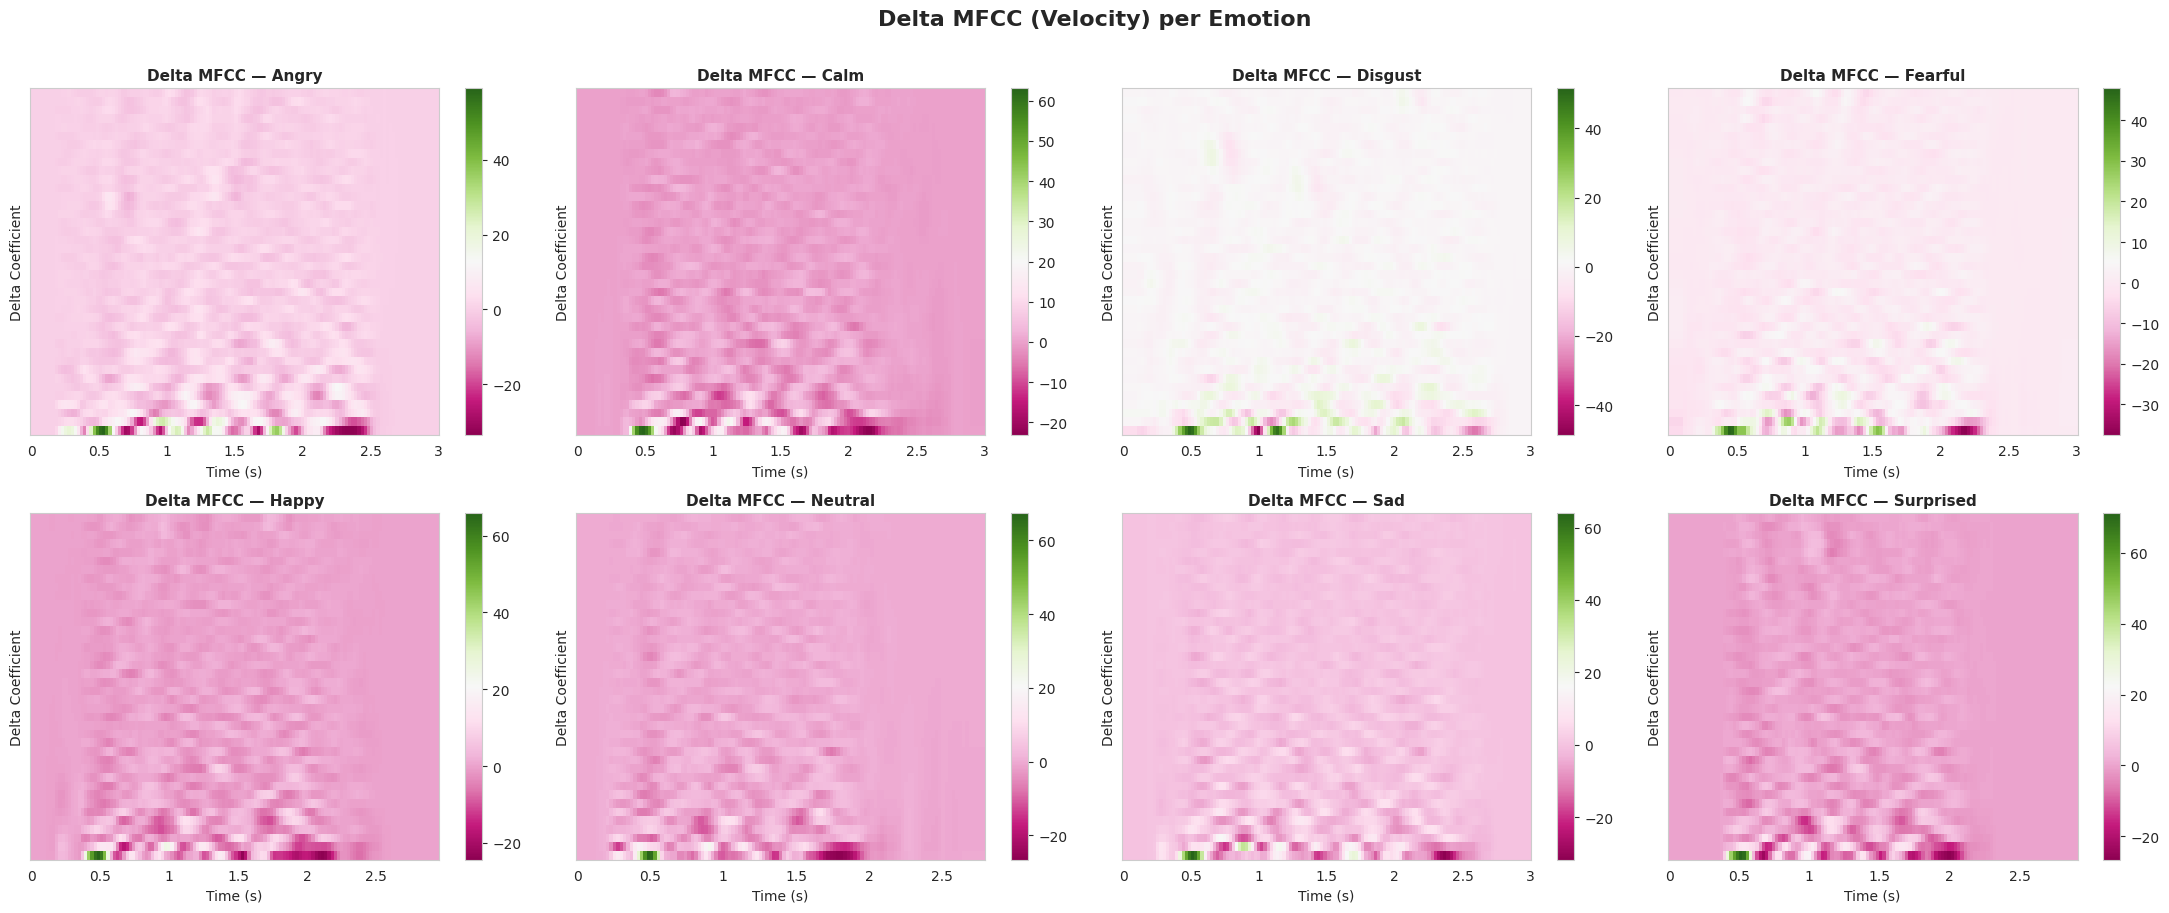

In [11]:
# MFCC Delta (1st order) per emosi
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
axes = axes.flatten()

for i, emo in enumerate(emotions_list):
    row = df[df['emotion'] == emo].iloc[0]
    y, sr = librosa.load(row['path'], duration=3.0, offset=0.5)
    mfcc  = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)
    delta = librosa.feature.delta(mfcc)
    img   = librosa.display.specshow(delta, x_axis='time', ax=axes[i],
                                     hop_length=512, sr=sr, cmap='PiYG')
    axes[i].set_title(f'Delta MFCC — {emo.capitalize()}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Time (s)')
    axes[i].set_ylabel('Delta Coefficient')
    plt.colorbar(img, ax=axes[i])

plt.suptitle('Delta MFCC (Velocity) per Emotion', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/07_delta_mfcc.png', dpi=150, bbox_inches='tight')
plt.show()

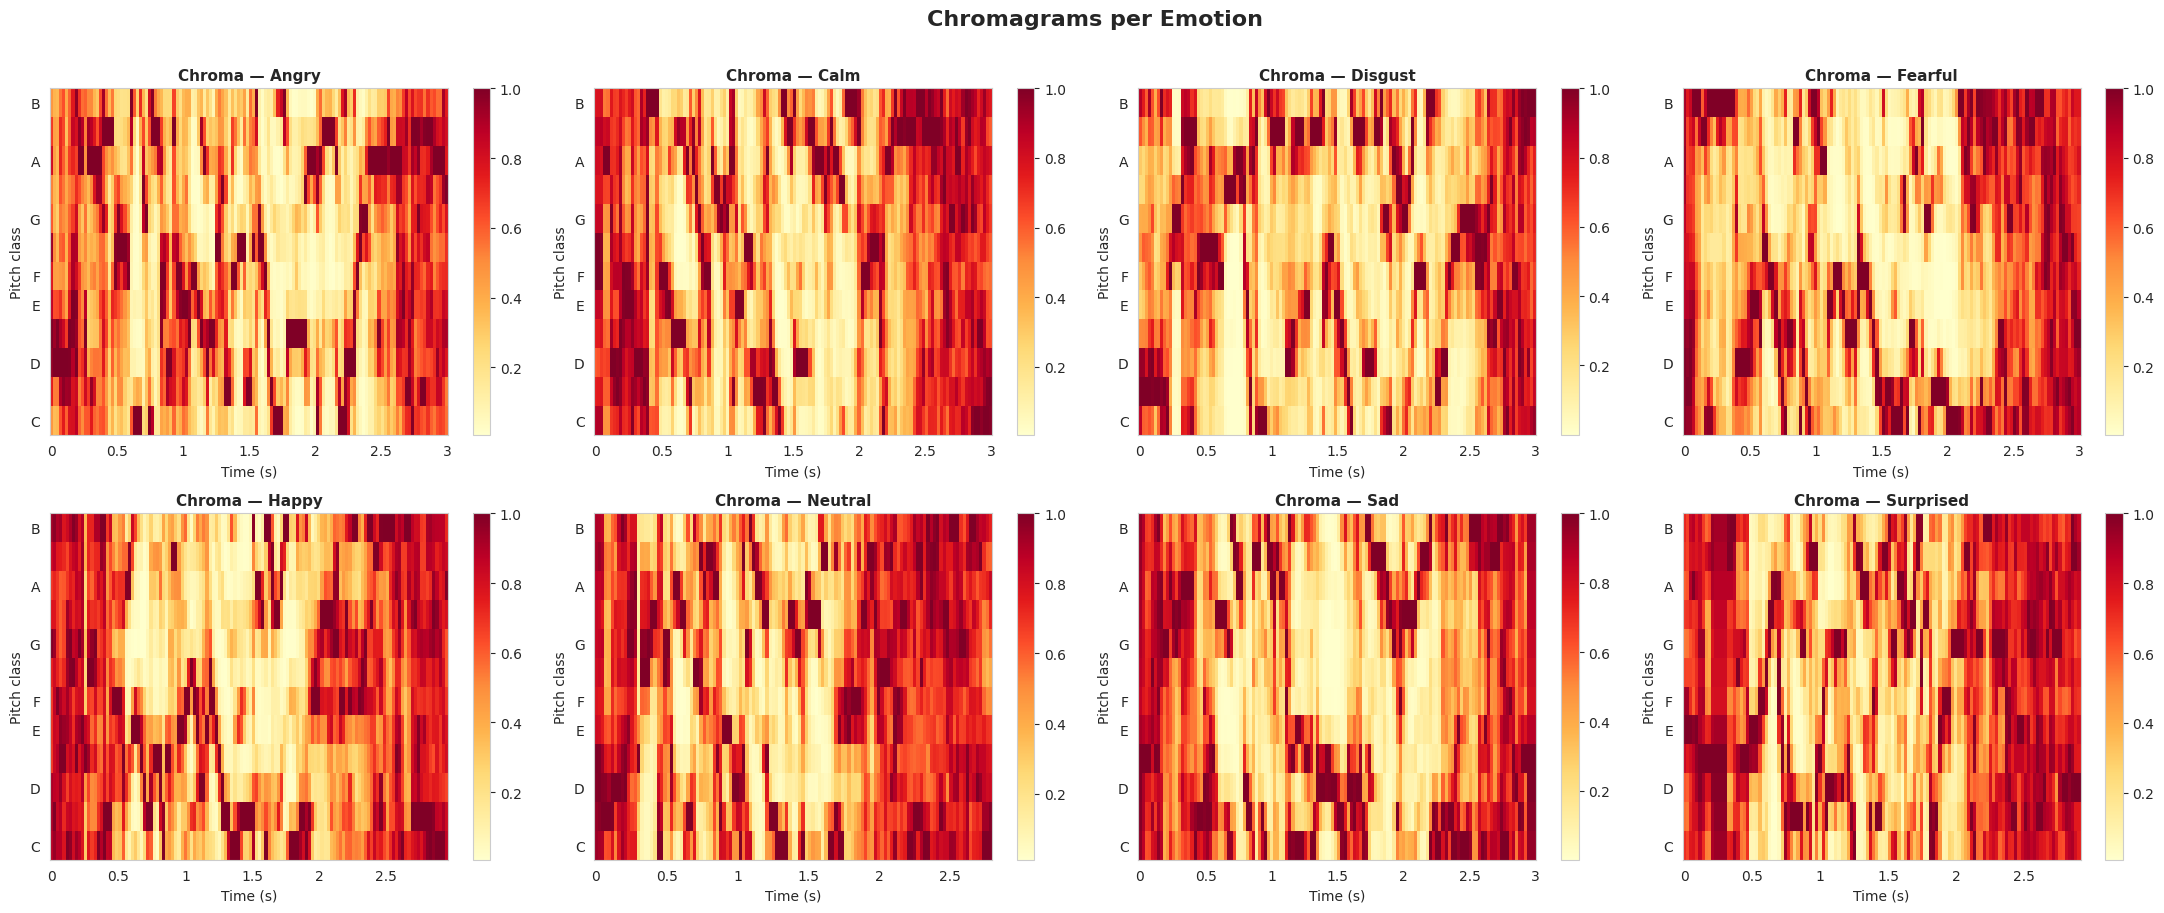

In [12]:
# Chromagram per emosi
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
axes = axes.flatten()

for i, emo in enumerate(emotions_list):
    row = df[df['emotion'] == emo].iloc[0]
    y, sr = librosa.load(row['path'], duration=3.0, offset=0.5)
    chroma = librosa.feature.chroma_stft(y=y, sr=sr, n_chroma=12)
    img    = librosa.display.specshow(chroma, y_axis='chroma', x_axis='time',
                                      ax=axes[i], sr=sr, cmap='YlOrRd')
    axes[i].set_title(f'Chroma — {emo.capitalize()}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Time (s)')
    plt.colorbar(img, ax=axes[i])

plt.suptitle('Chromagrams per Emotion', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/08_chromagrams.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
# Statistik audio per sample — durasi, energy, ZCR, pitch
print('Computing per-sample statistics (ini butuh beberapa menit)...')

durations, rmse_vals, zcr_vals, pitch_vals = [], [], [], []

for _, row in tqdm(df.iterrows(), total=len(df)):
    y, sr = librosa.load(row['path'], sr=22050)
    durations.append(librosa.get_duration(y=y, sr=sr))
    rmse_vals.append(float(np.sqrt(np.mean(y**2))))
    zcr_vals.append(float(np.mean(librosa.feature.zero_crossing_rate(y))))
    try:
        f0, _, _ = librosa.pyin(y, fmin=librosa.note_to_hz('C2'),
                                 fmax=librosa.note_to_hz('C7'), sr=sr)
        pitch_vals.append(float(np.nanmean(f0)) if f0 is not None else 0.0)
    except:
        pitch_vals.append(0.0)

df['duration']   = durations
df['rms_energy'] = rmse_vals
df['zcr']        = zcr_vals
df['mean_pitch'] = pitch_vals

print(df.groupby('emotion')[['duration','rms_energy','zcr','mean_pitch']].mean().round(4))

Computing per-sample statistics (ini butuh beberapa menit)...


100%|██████████| 1440/1440 [12:35<00:00,  1.91it/s]

           duration  rms_energy     zcr  mean_pitch
emotion                                            
angry        3.8714      0.0458  0.2456    413.1146
calm         3.7958      0.0043  0.2530    221.3739
disgust      3.9418      0.0107  0.2566    275.0194
fearful      3.5743      0.0276  0.2388    462.2555
happy        3.6382      0.0210  0.2485    363.2435
neutral      3.5032      0.0054  0.2714    224.2833
sad          3.6945      0.0086  0.2581    341.3616
surprised    3.4875      0.0142  0.2576    438.1608


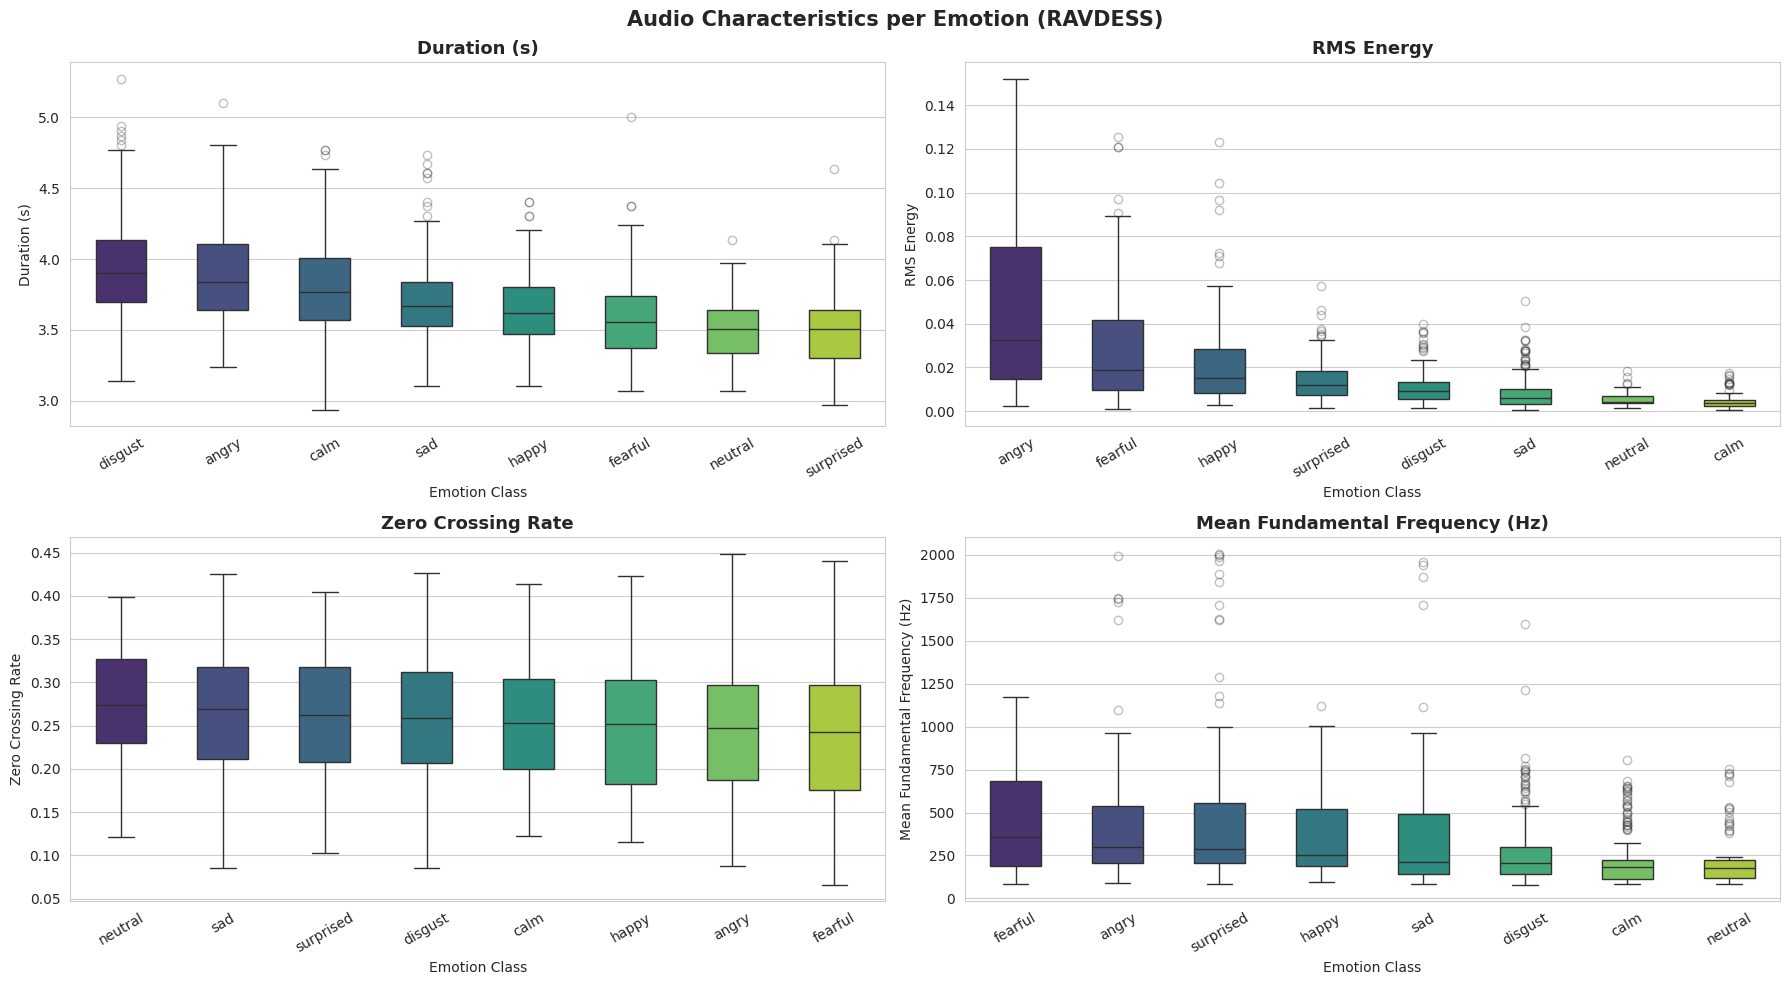

In [14]:
# Boxplot statistik per emosi
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
metrics = ['duration', 'rms_energy', 'zcr', 'mean_pitch']
titles  = ['Duration (s)', 'RMS Energy', 'Zero Crossing Rate', 'Mean Fundamental Frequency (Hz)']

for ax, metric, title in zip(axes.flatten(), metrics, titles):
    order = df.groupby('emotion')[metric].median().sort_values(ascending=False).index
    sns.boxplot(data=df, x='emotion', y=metric, order=order,
                palette='viridis', ax=ax, width=0.5, flierprops={'alpha':0.3})
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Emotion Class')
    ax.set_ylabel(title)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Audio Characteristics per Emotion (RAVDESS)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/09_audio_stats_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

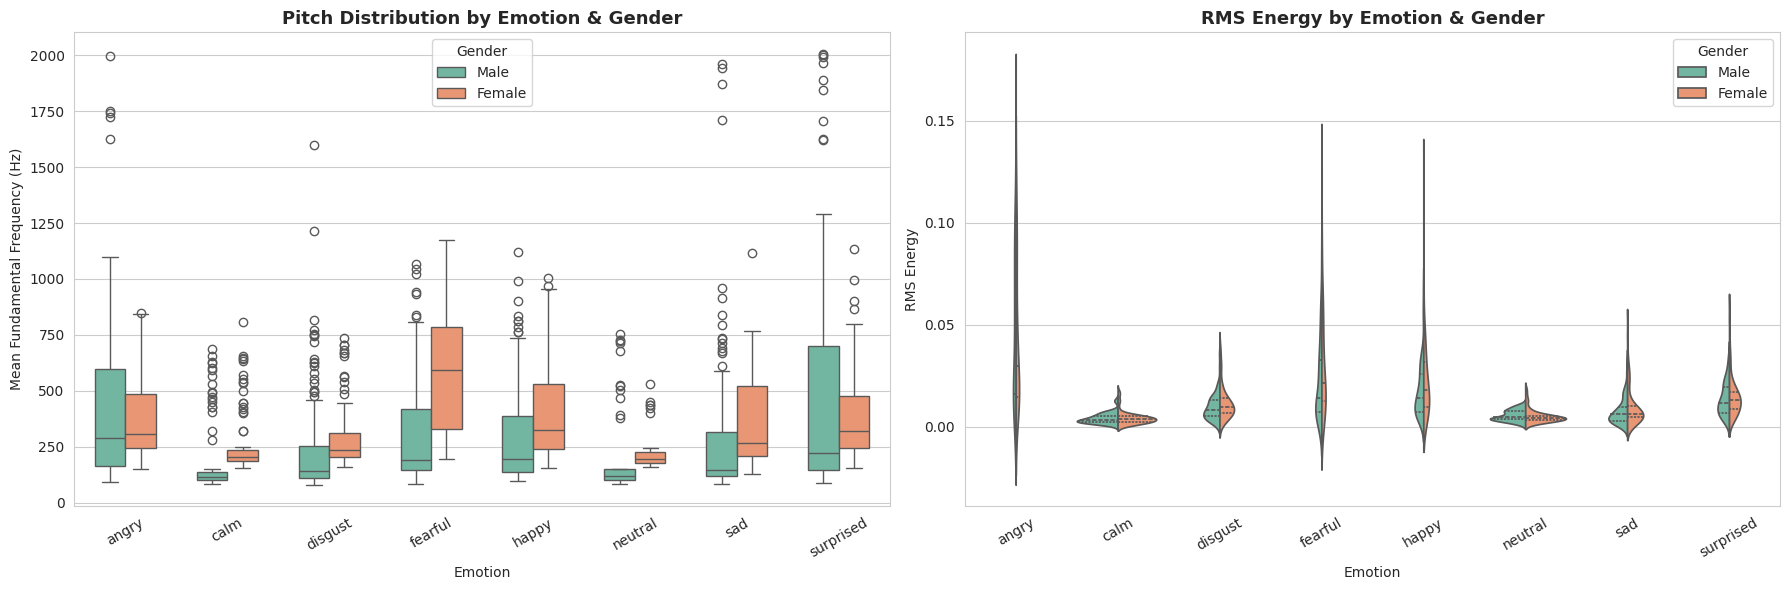

In [15]:
# Gender-based pitch dan energy
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.boxplot(data=df, x='emotion', y='mean_pitch', hue='gender',
            palette='Set2', ax=axes[0], order=emotions_list, width=0.6)
axes[0].set_title('Pitch Distribution by Emotion & Gender', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Emotion')
axes[0].set_ylabel('Mean Fundamental Frequency (Hz)')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend(title='Gender')

sns.violinplot(data=df, x='emotion', y='rms_energy', hue='gender',
               split=True, palette='Set2', ax=axes[1], order=emotions_list, inner='quart')
axes[1].set_title('RMS Energy by Emotion & Gender', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Emotion')
axes[1].set_ylabel('RMS Energy')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(title='Gender')

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/10_gender_pitch_energy.png', dpi=150, bbox_inches='tight')
plt.show()

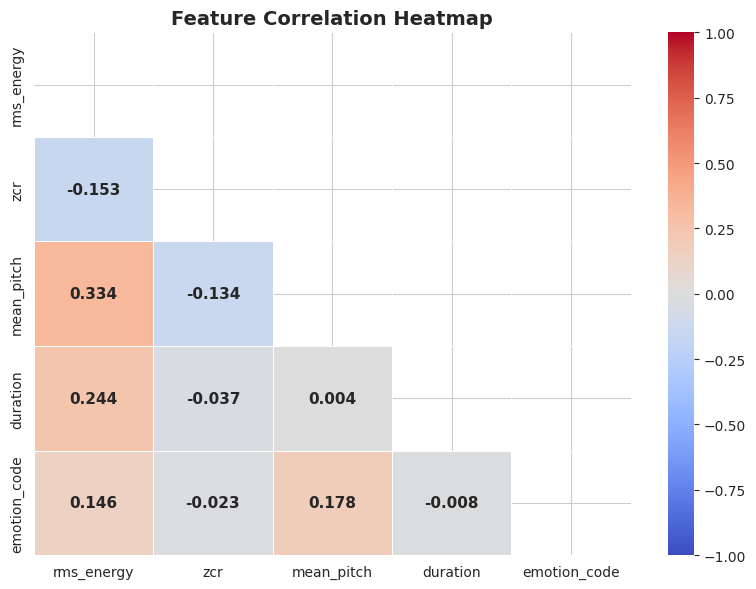

In [16]:
# Correlation heatmap antar fitur statistik
corr_cols = ['rms_energy','zcr','mean_pitch','duration','emotion_code']
corr_mat  = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(corr_mat, annot=True, fmt='.3f', cmap='coolwarm',
            mask=mask, ax=ax, vmin=-1, vmax=1,
            linewidths=0.5, linecolor='white',
            annot_kws={'size': 11, 'weight': 'bold'})
ax.set_title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/11_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

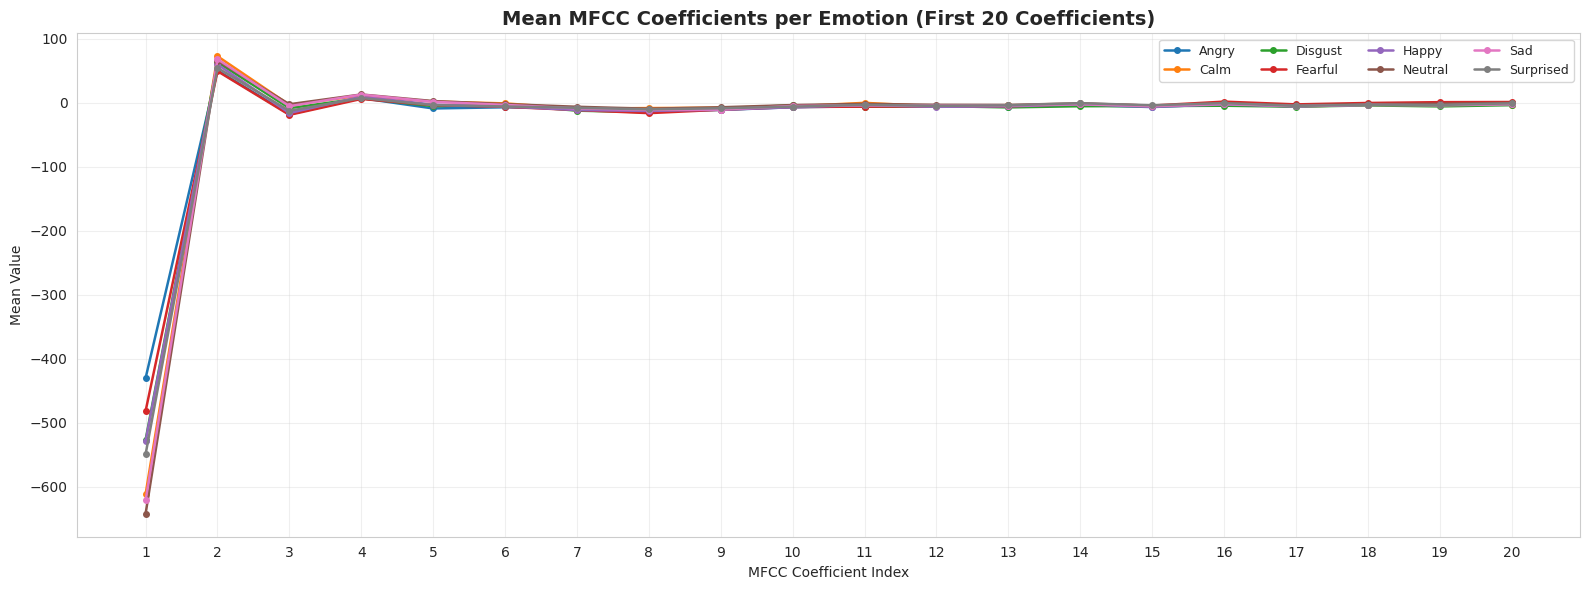

In [17]:
# MFCC mean coefficient comparison antar emosi
fig, ax = plt.subplots(figsize=(16, 6))

mfcc_means = {}
for emo in emotions_list:
    samples = df[df['emotion'] == emo].head(20)
    all_mfcc = []
    for _, row in samples.iterrows():
        y, sr = librosa.load(row['path'], duration=3.0, offset=0.5)
        mfcc  = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
        all_mfcc.append(np.mean(mfcc, axis=1))
    mfcc_means[emo] = np.mean(all_mfcc, axis=0)

for emo, vals in mfcc_means.items():
    ax.plot(range(1, 21), vals, marker='o', markersize=4, label=emo.capitalize(), linewidth=1.8)

ax.set_title('Mean MFCC Coefficients per Emotion (First 20 Coefficients)', fontsize=14, fontweight='bold')
ax.set_xlabel('MFCC Coefficient Index')
ax.set_ylabel('Mean Value')
ax.legend(ncol=4, fontsize=9)
ax.set_xticks(range(1, 21))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/12_mfcc_mean_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Audio playback — 1 sample male + female per emosi
print('=== Audio Playback Samples (Male & Female per Emotion) ===')
for emo in emotions_list:
    print(f'\n--- {emo.upper()} ---')
    for gender in ['Male', 'Female']:
        subset = df[(df['emotion'] == emo) & (df['gender'] == gender)]
        if len(subset) == 0:
            continue
        row = subset.iloc[0]
        y, sr = librosa.load(row['path'], duration=3.0, offset=0.5)
        print(f'  [{gender}] Actor {row["actor_id"]:02d} | Intensity: {row["intensity"]}')
        display(Audio(data=y, rate=sr))

=== Audio Playback Samples (Male & Female per Emotion) ===

--- ANGRY ---
  [Male] Actor 01 | Intensity: Normal


  [Female] Actor 02 | Intensity: Normal



--- CALM ---
  [Male] Actor 01 | Intensity: Normal


  [Female] Actor 02 | Intensity: Normal



--- DISGUST ---
  [Male] Actor 01 | Intensity: Normal


...

  [Female] Actor 02 | Intensity: Normal



--- SAD ---
  [Male] Actor 01 | Intensity: Normal


  [Female] Actor 02 | Intensity: Normal



--- SURPRISED ---
  [Male] Actor 01 | Intensity: Normal


  [Female] Actor 02 | Intensity: Normal


## 3. Data Augmentation

Mengikuti Latif et al. (2020) dan Zhao et al. (2019), saya menerapkan 6 teknik augmentasi untuk memperbesar dataset dan meningkatkan generalisasi model. Setiap audio menghasilkan 6 versi (termasuk original).

In [19]:
def add_noise(y, factor=0.005):
    amp = factor * np.random.uniform(0.1, 1.0) * np.amax(np.abs(y) + 1e-9)
    return (y + amp * np.random.normal(size=len(y))).astype(np.float32)

def pitch_shift(y, sr, n_steps):
    return librosa.effects.pitch_shift(y, sr=sr, n_steps=n_steps)

def time_stretch(y, rate):
    stretched = librosa.effects.time_stretch(y, rate=rate)
    return stretched

def volume_gain(y, gain_db):
    return (y * (10 ** (gain_db / 20.0))).astype(np.float32)

def combined_aug(y, sr):
    noised   = add_noise(y)
    shifted  = librosa.effects.pitch_shift(noised, sr=sr, n_steps=np.random.choice([-1, 1]))
    return shifted

print('Augmentation functions ready.')
print('Augmentations per sample: 6')
print('  1. Original')
print('  2. + Gaussian noise')
print('  3. Pitch shift +2 semitones')
print('  4. Pitch shift -2 semitones')
print('  5. Time stretch slow (rate=0.9)')
print('  6. Noise + pitch combined')

Augmentation functions ready.
Augmentations per sample: 6
  1. Original
  2. + Gaussian noise
  3. Pitch shift +2 semitones
  4. Pitch shift -2 semitones
  5. Time stretch slow (rate=0.9)
  6. Noise + pitch combined


## 4. Feature Extraction

Saya menggunakan representasi temporal MFCC + Delta + Delta-Delta (dimensi 120) yang dipadatkan ke panjang tetap 130 frame (~3 detik pada sr=22050, hop=512). Pendekatan ini mempertahankan informasi temporal yang krusial untuk CNN-BiLSTM sesuai dengan Chen et al. (2021).

In [20]:
N_MFCC     = 40
MAX_LEN    = 130
N_FEATURES = N_MFCC * 3    # mfcc + delta + delta2 = 120
SR         = 22050
HOP_LENGTH = 512

def extract_feat(y, sr):
    if len(y) < sr * 0.5:
        return None
    mfcc   = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC, hop_length=HOP_LENGTH)
    delta1 = librosa.feature.delta(mfcc)
    delta2 = librosa.feature.delta(mfcc, order=2)
    feat   = np.vstack([mfcc, delta1, delta2]).T.astype(np.float32)  # (T, 120)
    if feat.shape[0] < MAX_LEN:
        pad  = np.zeros((MAX_LEN - feat.shape[0], N_FEATURES), dtype=np.float32)
        feat = np.vstack([feat, pad])
    else:
        feat = feat[:MAX_LEN, :]
    return feat   # (130, 120)

def process_one(row):
    results_x, results_y = [], []
    try:
        y, sr = librosa.load(row['path'], sr=SR, duration=3.0, offset=0.5)
        augs  = [
            y,
            add_noise(y),
            pitch_shift(y, sr, n_steps=2),
            pitch_shift(y, sr, n_steps=-2),
            time_stretch(y, rate=0.9),
            combined_aug(y, sr),
        ]
        for aug_y in augs:
            feat = extract_feat(aug_y, sr)
            if feat is not None:
                results_x.append(feat)
                results_y.append(row['emotion'])
    except Exception:
        pass
    return results_x, results_y

print(f'Input shape per sample: ({MAX_LEN}, {N_FEATURES})')

Input shape per sample: (130, 120)


In [21]:
# Parallel feature extraction — memanfaatkan semua core CPU
start = timeit.default_timer()

results = Parallel(n_jobs=-1, verbose=0)(
    delayed(process_one)(row)
    for _, row in tqdm(df.iterrows(), total=len(df), desc='Extracting features')
)

X_list, y_list = [], []
for rx, ry in results:
    X_list.extend(rx)
    y_list.extend(ry)

X_arr = np.array(X_list, dtype=np.float32)
y_arr = np.array(y_list)

elapsed = timeit.default_timer() - start
print(f'Extraction complete in {elapsed:.1f}s')
print(f'X shape: {X_arr.shape}   ({X_arr.shape[0]} samples)')
print(f'y shape: {y_arr.shape}')
print(f'Class distribution:\n{pd.Series(y_arr).value_counts()}')

Extracting features: 100%|██████████| 1440/1440 [00:20<00:00, 71.37it/s]


Extraction complete in 20.7s
X shape: (8640, 130, 120)   (8640 samples)
y shape: (8640,)
Class distribution:
calm         1152
happy        1152
sad          1152
angry        1152
fearful      1152
disgust      1152
surprised    1152
neutral       576
Name: count, dtype: int64


In [22]:
# Simpan features ke disk
np.save(f'{FEAT_DIR}/X_features.npy', X_arr)
np.save(f'{FEAT_DIR}/y_labels.npy',   y_arr)
print(f'Features saved to {FEAT_DIR}/')

Features saved to output/features/


## 5. Data Preparation

In [23]:
X_arr = np.load(f'{FEAT_DIR}/X_features.npy')
y_arr = np.load(f'{FEAT_DIR}/y_labels.npy')
print(f'X: {X_arr.shape}, y: {y_arr.shape}')

le = LabelEncoder()
y_enc = le.fit_transform(y_arr)
n_classes = len(le.classes_)
y_cat = to_categorical(y_enc, num_classes=n_classes)

with open(f'{MODEL_DIR}/label_encoder.pkl', 'wb') as f:
    pickle.dump(le, f)

print(f'Classes ({n_classes}): {list(le.classes_)}')

X: (8640, 130, 120), y: (8640,)
Classes (8): [np.str_('angry'), np.str_('calm'), np.str_('disgust'), np.str_('fearful'), np.str_('happy'), np.str_('neutral'), np.str_('sad'), np.str_('surprised')]


In [24]:
# Stratified split: 70% train | 15% val | 15% test
X_temp, X_test, y_temp, y_test_cat = train_test_split(
    X_arr, y_cat, test_size=0.15, random_state=42, stratify=y_enc
)
y_temp_enc = np.argmax(y_temp, axis=1)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1765, random_state=42, stratify=y_temp_enc
)

print(f'Train : {X_train.shape[0]:>6} samples')
print(f'Val   : {X_val.shape[0]:>6} samples')
print(f'Test  : {X_test.shape[0]:>6} samples')

Train :   6047 samples
Val   :   1297 samples
Test  :   1296 samples


In [25]:
# StandardScaler — fit pada train, transform semua split
scaler = StandardScaler()
n_tr, T, F = X_train.shape

X_train_s = scaler.fit_transform(X_train.reshape(-1, F)).reshape(n_tr, T, F)
X_val_s   = scaler.transform(X_val.reshape(-1, F)).reshape(X_val.shape[0], T, F)
X_test_s  = scaler.transform(X_test.reshape(-1, F)).reshape(X_test.shape[0], T, F)

with open(f'{MODEL_DIR}/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print(f'Scaled train: {X_train_s.shape}')
print(f'Input shape for model: (batch, {T}, {F})')

Scaled train: (6047, 130, 120)
Input shape for model: (batch, 130, 120)


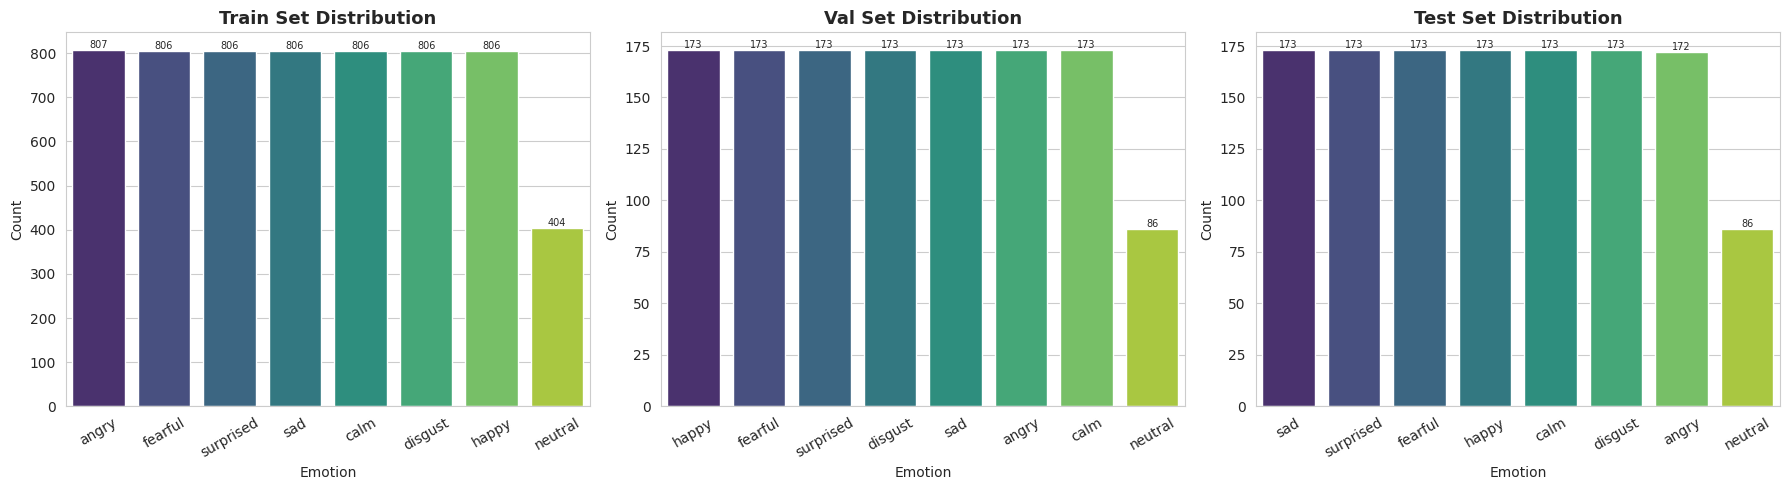

In [26]:
# Verifikasi distribusi per split
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
splits = [
    ('Train', np.argmax(y_train, axis=1)),
    ('Val',   np.argmax(y_val,   axis=1)),
    ('Test',  np.argmax(y_test_cat, axis=1)),
]

for ax, (name, ysplit) in zip(axes, splits):
    counts = pd.Series(le.inverse_transform(ysplit)).value_counts()
    sns.barplot(x=counts.index, y=counts.values, palette='viridis', ax=ax)
    ax.set_title(f'{name} Set Distribution', fontsize=13, fontweight='bold')
    ax.set_xlabel('Emotion')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=30)
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}',
                    (p.get_x()+p.get_width()/2., p.get_height()),
                    ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/13_split_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Hyperparameter Tuning

Saya menggunakan **Bayesian Optimization** dari keras-tuner dengan 30 trial (8 random initialization + 22 guided search). Setiap trial dijalankan hingga 40 epoch dengan EarlyStopping patience=8. Search space mencakup:
- CNN filter sizes (conv1: 256/512, conv2: 128/256, conv3: 64/128)
- LSTM units (BiLSTM 1: 128/192/256, BiLSTM 2: 64/96/128)
- Multi-Head Attention heads (2/4/8)
- Dropout rates (0.1–0.4)
- Learning rate (5e-5 – 5e-3, log scale)
- Dense units (128/256/512)

In [27]:
INPUT_SHAPE = (MAX_LEN, N_FEATURES)

def build_model(hp):
    f1 = hp.Choice('conv1_filters', [256, 512])
    f2 = hp.Choice('conv2_filters', [128, 256])
    f3 = hp.Choice('conv3_filters', [64, 128])
    ks = hp.Choice('kernel_size',   [3, 5])
    l1 = hp.Choice('lstm1_units',   [128, 192, 256])
    l2 = hp.Choice('lstm2_units',   [64,  96,  128])
    d1 = hp.Choice('dense_units',   [128, 256, 512])
    dr_cnn  = hp.Float('dropout_cnn',   0.1, 0.4, step=0.05)
    dr_lstm = hp.Float('dropout_lstm',  0.1, 0.4, step=0.05)
    dr_den  = hp.Float('dropout_dense', 0.1, 0.4, step=0.05)
    nh      = hp.Choice('num_heads',    [2, 4, 8])
    lr      = hp.Float('lr', 5e-5, 5e-3, sampling='log')

    inp = Input(shape=INPUT_SHAPE)

    # CNN Block 1
    x = Conv1D(f1, ks, padding='same', activation='relu')(inp)
    x = BatchNormalization()(x)
    x = MaxPooling1D(2)(x)
    x = Dropout(dr_cnn)(x)

    # CNN Block 2
    x = Conv1D(f2, ks, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(2)(x)
    x = Dropout(dr_cnn)(x)

    # CNN Block 3
    x = Conv1D(f3, ks, padding='same', activation='relu')(x)
    x = BatchNormalization()(x)
    x = MaxPooling1D(2)(x)

    # BiLSTM
    x = Bidirectional(LSTM(l1, return_sequences=True))(x)
    x = Dropout(dr_lstm)(x)
    x = Bidirectional(LSTM(l2, return_sequences=True))(x)

    # Multi-Head Self-Attention (Vaswani et al., 2017)
    key_dim = max(16, (l2 * 2) // max(nh, 1))
    attn    = MultiHeadAttention(num_heads=nh, key_dim=key_dim, dropout=0.1)(x, x)
    x       = LayerNormalization(epsilon=1e-6)(Add()([x, attn]))

    x = GlobalAveragePooling1D()(x)
    x = Dense(d1, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dr_den)(x)

    out = Dense(n_classes, activation='softmax')(x)

    model = Model(inp, out)
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

print('Model builder defined. Search space ready.')

Model builder defined. Search space ready.


In [28]:
tuner = kt.BayesianOptimization(
    hypermodel=build_model,
    objective=kt.Objective('val_accuracy', direction='max'),
    max_trials=30,
    num_initial_points=8,
    directory=HP_DIR,
    project_name='ser_cnn_bilstm_v1',
    overwrite=True
)

print('Tuner initialized.')
tuner.search_space_summary()

I0000 00:00:1776141826.918058   10660 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9882 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:01:00.0, compute capability: 8.6


Tuner initialized.
Search space summary
Default search space size: 12
conv1_filters (Choice)
{'default': 256, 'conditions': [], 'values': [256, 512], 'ordered': True}
conv2_filters (Choice)
{'default': 128, 'conditions': [], 'values': [128, 256], 'ordered': True}
conv3_filters (Choice)
{'default': 64, 'conditions': [], 'values': [64, 128], 'ordered': True}
kernel_size (Choice)
{'default': 3, 'conditions': [], 'values': [3, 5], 'ordered': True}
lstm1_units (Choice)
{'default': 128, 'conditions': [], 'values': [128, 192, 256], 'ordered': True}
lstm2_units (Choice)
{'default': 64, 'conditions': [], 'values': [64, 96, 128], 'ordered': True}
dense_units (Choice)
{'default': 128, 'conditions': [], 'values': [128, 256, 512], 'ordered': True}
dropout_cnn (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.4, 'step': 0.05, 'sampling': 'linear'}
dropout_lstm (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.4, 'step': 0.05, 'sampling': 'linear'}


In [29]:
es_tune  = EarlyStopping(monitor='val_accuracy', patience=8,
                          restore_best_weights=True, verbose=0)
rlr_tune = ReduceLROnPlateau(monitor='val_accuracy', factor=0.5,
                              patience=4, min_lr=1e-7, verbose=0)

print('Starting Bayesian search — 30 trials, up to 40 epochs each')
tuner.search(
    X_train_s, y_train,
    epochs=40,
    validation_data=(X_val_s, y_val),
    batch_size=32,
    callbacks=[es_tune, rlr_tune],
    verbose=1
)
print('\nSearch completed.')

Trial 30 Complete [00h 01m 21s]
val_accuracy: 0.9676175713539124

Best val_accuracy So Far: 0.9799537658691406
Total elapsed time: 00h 48m 07s

Search completed.


In [30]:
# Hasil 5 trial terbaik
tuner.results_summary(num_trials=5)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print('\nBest Hyperparameters Found:')
for k, v in sorted(best_hp.values.items()):
    print(f'  {k:20s}: {v}')

with open(f'{MODEL_DIR}/best_hp.json', 'w') as f:
    json.dump(best_hp.values, f, indent=2)
print(f'\nSaved: {MODEL_DIR}/best_hp.json')

Results summary
Results in output/hp_tuning/ser_cnn_bilstm_v1
Showing 5 best trials
Objective(name="val_accuracy", direction="max")

Trial 27 summary
Hyperparameters:
conv1_filters: 256
conv2_filters: 256
conv3_filters: 128
kernel_size: 5
lstm1_units: 256
lstm2_units: 64
dense_units: 128
dropout_cnn: 0.35
dropout_lstm: 0.4
dropout_dense: 0.4
num_heads: 2
lr: 0.0019205791733062558
Score: 0.9799537658691406

Trial 06 summary
Hyperparameters:
conv1_filters: 512
conv2_filters: 256
conv3_filters: 128
kernel_size: 5
lstm1_units: 256
lstm2_units: 64
dense_units: 128
dropout_cnn: 0.4
dropout_lstm: 0.35
dropout_dense: 0.2
num_heads: 4
lr: 0.0008557810769639211
Score: 0.9737856388092041

Trial 16 summary
Hyperparameters:
conv1_filters: 512
conv2_filters: 256
conv3_filters: 128
kernel_size: 5
lstm1_units: 256
lstm2_units: 64
dense_units: 128
dropout_cnn: 0.35
dropout_lstm: 0.30000000000000004
dropout_dense: 0.25
num_heads: 4
lr: 0.0009198833752751002
Score: 0.9722436666488647

Trial 10 summary
Hy

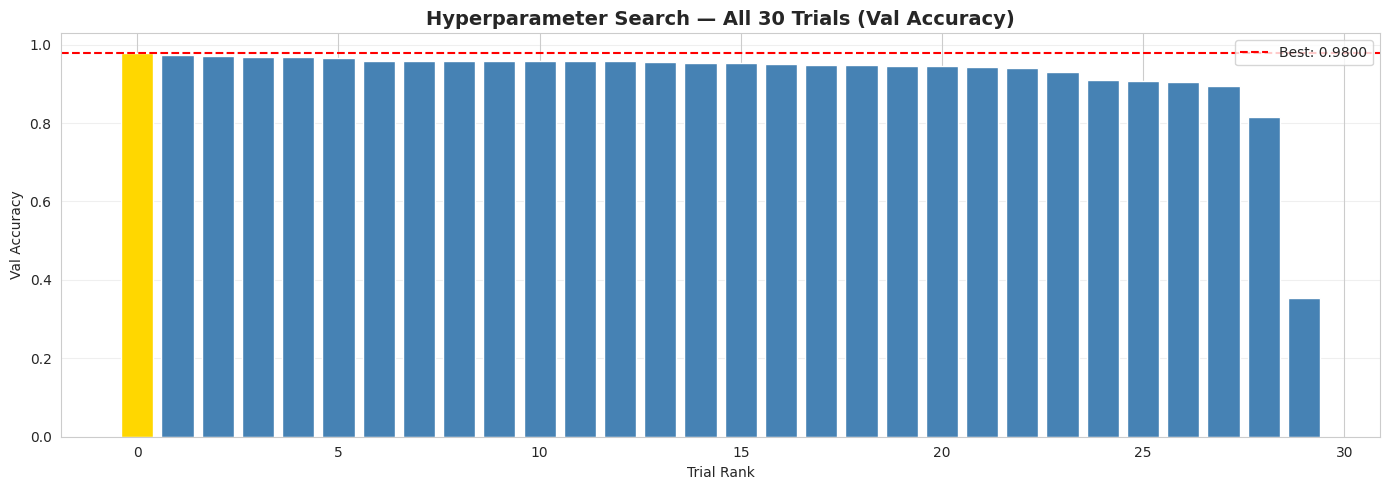

  trial_id  val_accuracy
0       27      0.979954
1       06      0.973786
2       16      0.972244
3       10      0.968389
4       29      0.967618


In [31]:
# Visualisasi trial accuracy dari semua percobaan tuning
trial_results = []
for trial in tuner.oracle.trials.values():
    if trial.score is not None:
        trial_results.append({'trial_id': trial.trial_id, 'val_accuracy': trial.score})

trial_df = pd.DataFrame(trial_results).sort_values('val_accuracy', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(14, 5))
colors = ['gold' if i == 0 else 'steelblue' for i in range(len(trial_df))]
ax.bar(range(len(trial_df)), trial_df['val_accuracy'], color=colors, edgecolor='white')
ax.axhline(trial_df['val_accuracy'].max(), color='red', ls='--', lw=1.5,
           label=f'Best: {trial_df["val_accuracy"].max():.4f}')
ax.set_title('Hyperparameter Search — All 30 Trials (Val Accuracy)', fontsize=14, fontweight='bold')
ax.set_xlabel('Trial Rank')
ax.set_ylabel('Val Accuracy')
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/14_hp_tuning_results.png', dpi=150, bbox_inches='tight')
plt.show()
print(trial_df.head(5))

## 7. Model Training

Training dilakukan dalam dua fase:
- **Phase 1:** Training penuh dari best HP, 100 epoch, EarlyStopping patience=15
- **Phase 2:** Fine-tuning dengan LR sangat kecil (1e-5), batch lebih kecil (16)

In [32]:
model = tuner.hypermodel.build(best_hp)
model.summary()

try:
    tf.keras.utils.plot_model(
        model, to_file=f'{PLOT_DIR}/model_architecture.png',
        show_shapes=True, show_layer_names=True, dpi=80
    )
    print(f'Architecture saved: {PLOT_DIR}/model_architecture.png')
except:
    print('(plot_model tidak tersedia, lanjutkan.)')

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 130, 120)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 130, 256)  │    153,856 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 130, 256)  │      1,024 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 65, 256)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 65, 256)   │          0 │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 65, 256)   │    327,936 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 65, 256)   │      1,024 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_4     │ (None, 32, 256)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 32, 256)   │          0 │ max_pooling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 32, 128)   │    163,968 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 128)   │        512 │ conv1d_5[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 16, 128)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_2     │ (None, 16, 512)   │    788,480 │ max_pooling1d_5[… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 16, 512)   │          0 │ bidirectional_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_3     │ (None, 16, 128)   │    295,424 │ dropout_7[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 16, 128)   │     66,048 │ bidirectional_3[… │
│ (MultiHeadAttentio… │                   │            │ bidirectional_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 16, 128)   │          0 │ bidirectional_3[… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16, 128)   │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ layer_normalizat

 Total params: 1,816,584 (6.93 MB)

 Trainable params: 1,815,048 (6.92 MB)

 Non-trainable params: 1,536 (6.00 KB)

You must install pydot (`pip install pydot`) for `plot_model` to work.
Architecture saved: output/plots/model_architecture.png


In [33]:
# Phase 1 callbacks
cbs_p1 = [
    ModelCheckpoint(f'{MODEL_DIR}/best_p1.keras',
                    monitor='val_accuracy', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_accuracy', patience=15,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_accuracy', factor=0.5,
                      patience=7, min_lr=1e-7, verbose=1),
    CSVLogger(f'{OUTPUT_DIR}/log_phase1.csv')
]

print('Phase 1 training...')
history = model.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=100,
    batch_size=32,
    callbacks=cbs_p1,
    verbose=1
)

best_p1_acc = max(history.history['val_accuracy'])
print(f'\nPhase 1 Best Val Accuracy: {best_p1_acc*100:.2f}%')

Phase 1 training...
Epoch 1/100
186/189 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.2959 - loss: 1.9591
Epoch 1: val_accuracy improved from None to 0.39399, saving model to output/models/best_p1.keras

Epoch 1: finished saving model to output/models/best_p1.keras
189/189 ━━━━━━━━━━━━━━━━━━━━ 6s 15ms/step - accuracy: 0.3893 - loss: 1.6618 - val_accuracy: 0.3940 - val_loss: 1.7695 - learning_rate: 0.0019
Epoch 2/100
186/189 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5772 - loss: 1.1265
Epoch 2: val_accuracy improved from 0.39399 to 0.49884, saving model to output/models/best_p1.keras

Epoch 2: finished saving model to output/models/best_p1.keras
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6172 - loss: 1.0362 - val_accuracy: 0.4988 - val_loss: 1.6131 - learning_rate: 0.0019
Epoch 3/100
186/189 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7169 - loss: 0.7932
Epoch 3: val_accuracy improved from 0.49884 to 0.69468, saving model to output/models/best_p1.keras

Epoch 3:

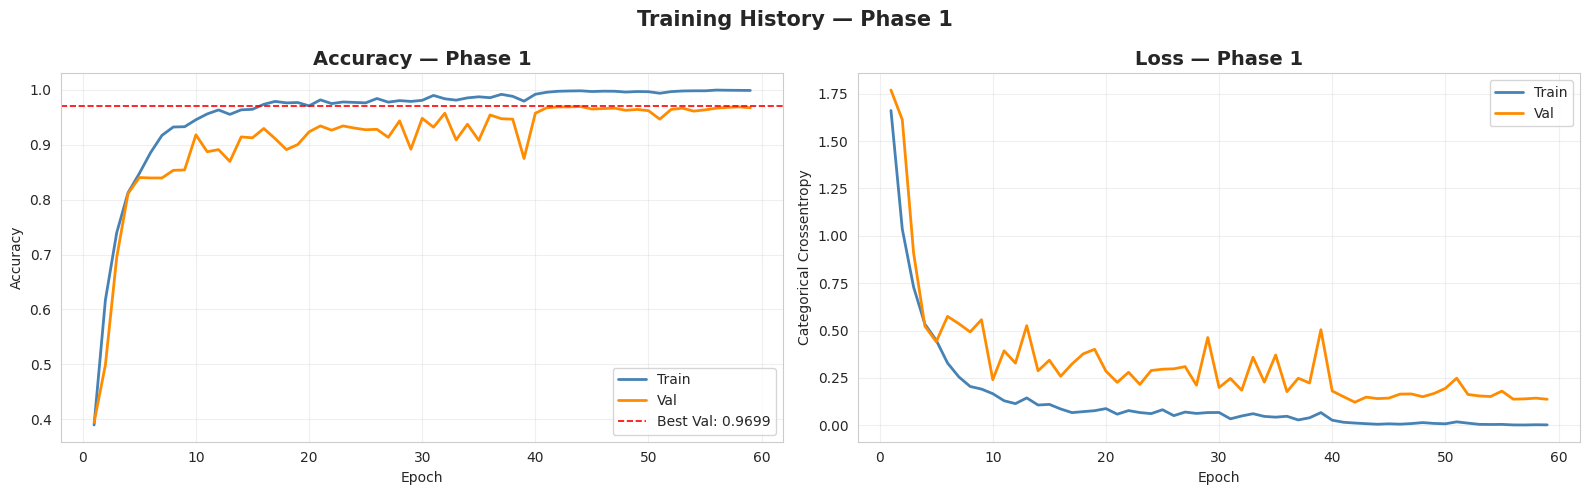

In [34]:
# Training curve Phase 1
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ep = range(1, len(history.history['accuracy']) + 1)

axes[0].plot(ep, history.history['accuracy'],     label='Train', lw=2, color='steelblue')
axes[0].plot(ep, history.history['val_accuracy'], label='Val',   lw=2, color='darkorange')
axes[0].axhline(best_p1_acc, color='red', ls='--', lw=1.2,
                label=f'Best Val: {best_p1_acc:.4f}')
axes[0].set_title('Accuracy — Phase 1', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(ep, history.history['loss'],     label='Train', lw=2, color='steelblue')
axes[1].plot(ep, history.history['val_loss'], label='Val',   lw=2, color='darkorange')
axes[1].set_title('Loss — Phase 1', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Categorical Crossentropy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Training History — Phase 1', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/15_training_phase1.png', dpi=150, bbox_inches='tight')
plt.show()

In [35]:
# Phase 2 — Fine-tuning dengan LR kecil
model = load_model(f'{MODEL_DIR}/best_p1.keras')
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cbs_p2 = [
    ModelCheckpoint(f'{MODEL_DIR}/best_p2.keras',
                    monitor='val_accuracy', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_accuracy', patience=20,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_accuracy', factor=0.3,
                      patience=8, min_lr=1e-9, verbose=1),
    CSVLogger(f'{OUTPUT_DIR}/log_phase2.csv')
]

print('Phase 2 fine-tuning...')
history_ft = model.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=60,
    batch_size=16,
    callbacks=cbs_p2,
    verbose=1
)

best_ft_acc = max(history_ft.history['val_accuracy'])
print(f'\nPhase 2 Best Val Accuracy: {best_ft_acc*100:.2f}%')

Phase 2 fine-tuning...
Epoch 1/60
378/378 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9955 - loss: 0.0113
Epoch 1: val_accuracy improved from None to 0.97147, saving model to output/models/best_p2.keras

Epoch 1: finished saving model to output/models/best_p2.keras
378/378 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9954 - loss: 0.0133 - val_accuracy: 0.9715 - val_loss: 0.1342 - learning_rate: 1.0000e-05
Epoch 2/60
378/378 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9975 - loss: 0.0117
Epoch 2: val_accuracy improved from 0.97147 to 0.97224, saving model to output/models/best_p2.keras

Epoch 2: finished saving model to output/models/best_p2.keras
378/378 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9962 - loss: 0.0133 - val_accuracy: 0.9722 - val_loss: 0.1306 - learning_rate: 1.0000e-05
Epoch 3/60
375/378 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9974 - loss: 0.0091
Epoch 3: val_accuracy improved from 0.97224 to 0.97301, saving model to output/models/best_p2.keras



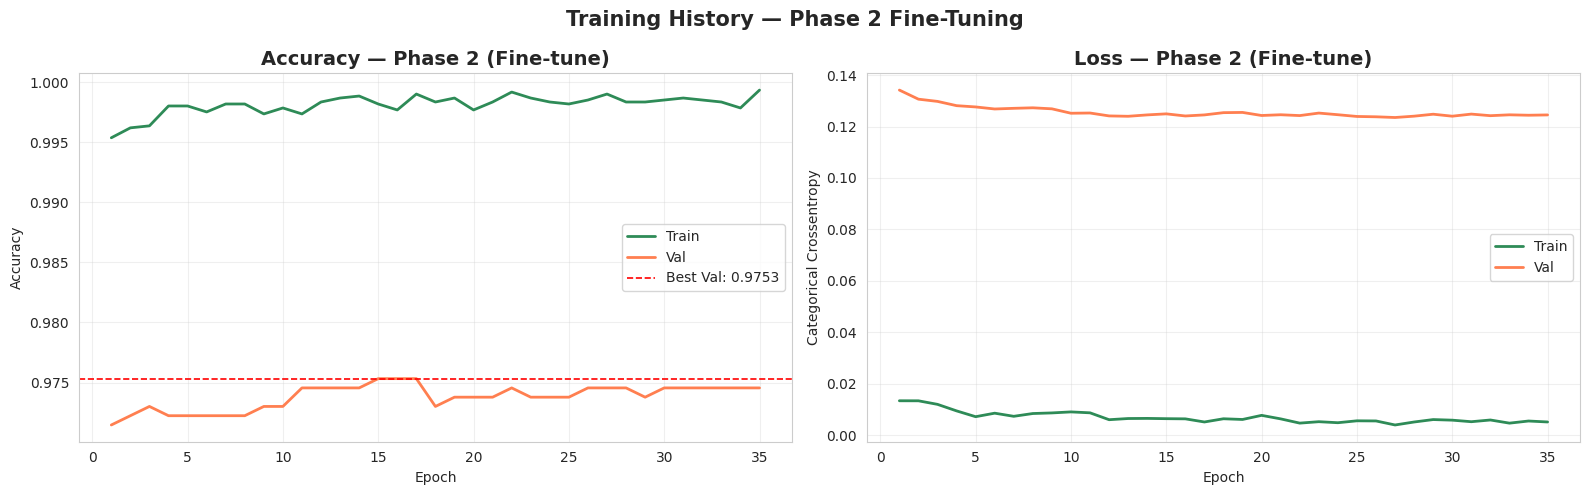

In [36]:
# Training curve Phase 2
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ep2 = range(1, len(history_ft.history['accuracy']) + 1)

axes[0].plot(ep2, history_ft.history['accuracy'],     label='Train', lw=2, color='seagreen')
axes[0].plot(ep2, history_ft.history['val_accuracy'], label='Val',   lw=2, color='coral')
axes[0].axhline(best_ft_acc, color='red', ls='--', lw=1.2,
                label=f'Best Val: {best_ft_acc:.4f}')
axes[0].set_title('Accuracy — Phase 2 (Fine-tune)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(ep2, history_ft.history['loss'],     label='Train', lw=2, color='seagreen')
axes[1].plot(ep2, history_ft.history['val_loss'], label='Val',   lw=2, color='coral')
axes[1].set_title('Loss — Phase 2 (Fine-tune)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Categorical Crossentropy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Training History — Phase 2 Fine-Tuning', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/16_training_phase2.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Evaluation

Evaluasi dilakukan pada **test set** yang sepenuhnya terpisah dari proses training dan tuning.

In [37]:
# Load best fine-tuned model
model = load_model(f'{MODEL_DIR}/best_p2.keras')

loss, accuracy = model.evaluate(X_test_s, y_test_cat, batch_size=32, verbose=0)
print(f'Test Loss     : {loss:.4f}')
print(f'Test Accuracy : {accuracy*100:.2f}%')
print(f'Phase 1 Best Val : {best_p1_acc*100:.2f}%')
print(f'Phase 2 Best Val : {best_ft_acc*100:.2f}%')

Test Loss     : 0.1170
Test Accuracy : 97.22%
Phase 1 Best Val : 96.99%
Phase 2 Best Val : 97.53%


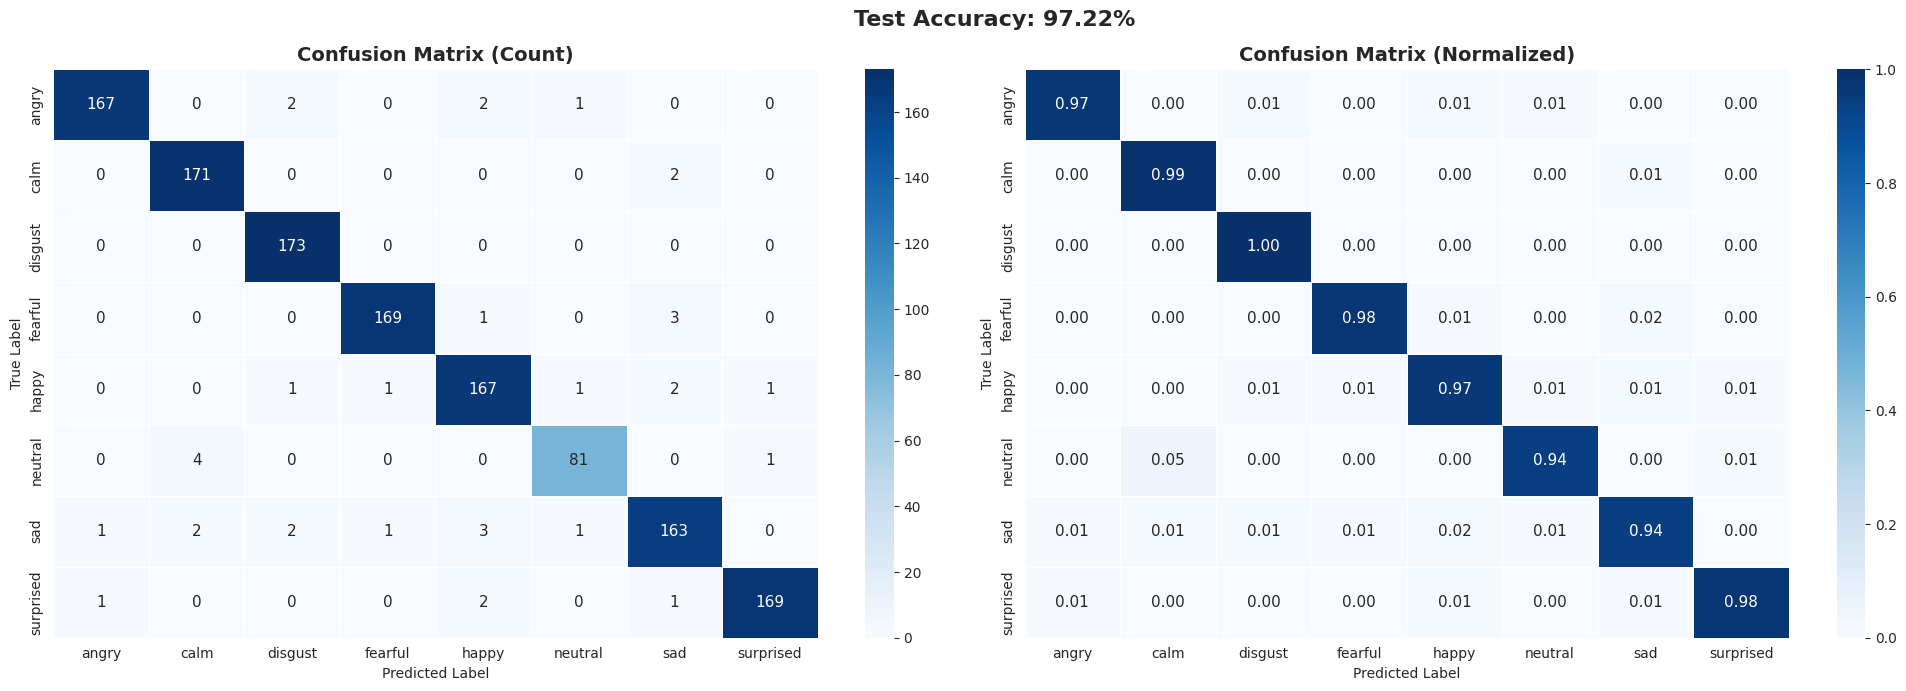

In [38]:
# Confusion Matrix — raw dan normalized
y_pred_prob = model.predict(X_test_s, batch_size=32, verbose=0)
y_pred      = np.argmax(y_pred_prob, axis=1)
y_true      = np.argmax(y_test_cat,  axis=1)
class_names = list(le.classes_)

cm      = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, linecolor='white', ax=axes[0],
            annot_kws={'size': 11})
axes[0].set_title('Confusion Matrix (Count)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, linecolor='white', ax=axes[1],
            vmin=0, vmax=1, annot_kws={'size': 11})
axes[1].set_title('Confusion Matrix (Normalized)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.suptitle(f'Test Accuracy: {accuracy*100:.2f}%', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/17_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

              precision    recall  f1-score   support

       angry     0.9882    0.9709    0.9795       172
        calm     0.9661    0.9884    0.9771       173
     disgust     0.9719    1.0000    0.9858       173
     fearful     0.9883    0.9769    0.9826       173
       happy     0.9543    0.9653    0.9598       173
     neutral     0.9643    0.9419    0.9529        86
         sad     0.9532    0.9422    0.9477       173
   surprised     0.9883    0.9769    0.9826       173

    accuracy                         0.9722      1296
   macro avg     0.9718    0.9703    0.9710      1296
weighted avg     0.9723    0.9722    0.9722      1296



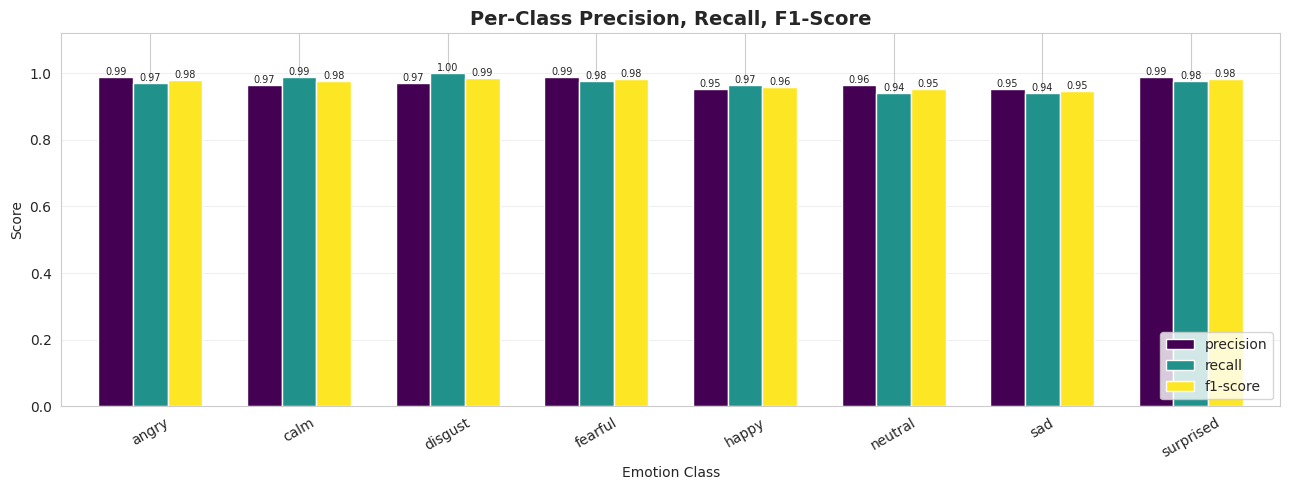

In [39]:
# Classification report
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

report      = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
report_df   = pd.DataFrame(report).transpose()

metrics_df  = report_df.iloc[:n_classes][['precision','recall','f1-score']]

fig, ax = plt.subplots(figsize=(13, 5))
metrics_df.plot(kind='bar', ax=ax, colormap='viridis', edgecolor='white', width=0.7)
ax.set_title('Per-Class Precision, Recall, F1-Score', fontsize=14, fontweight='bold')
ax.set_xlabel('Emotion Class')
ax.set_ylabel('Score')
ax.set_ylim([0, 1.12])
ax.tick_params(axis='x', rotation=30)
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}',
                (p.get_x()+p.get_width()/2., p.get_height()),
                ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/18_per_class_metrics.png', dpi=150, bbox_inches='tight')
plt.show()

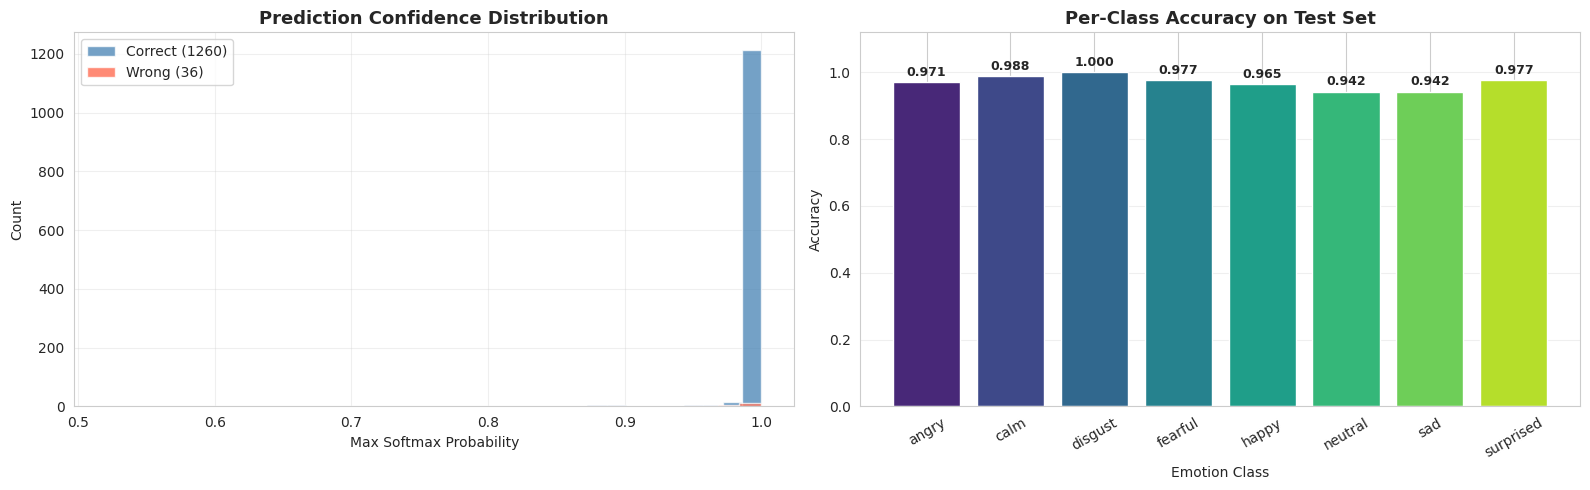

In [40]:
# Confidence distribution dan per-class accuracy
max_probs = np.max(y_pred_prob, axis=1)
correct   = (y_pred == y_true)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(max_probs[correct],  bins=30, alpha=0.75, color='steelblue',  label=f'Correct ({correct.sum()})')
axes[0].hist(max_probs[~correct], bins=30, alpha=0.75, color='tomato',     label=f'Wrong ({(~correct).sum()})')
axes[0].set_title('Prediction Confidence Distribution', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Max Softmax Probability')
axes[0].set_ylabel('Count')
axes[0].legend()
axes[0].grid(alpha=0.3)

per_class_acc = cm.diagonal() / cm.sum(axis=1)
bars = axes[1].bar(class_names, per_class_acc,
                   color=sns.color_palette('viridis', n_classes), edgecolor='white')
axes[1].set_title('Per-Class Accuracy on Test Set', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Emotion Class')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim([0, 1.12])
axes[1].tick_params(axis='x', rotation=30)
for bar, val in zip(bars, per_class_acc):
    axes[1].text(bar.get_x()+bar.get_width()/2., val+0.01,
                 f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/19_confidence_per_class.png', dpi=150, bbox_inches='tight')
plt.show()

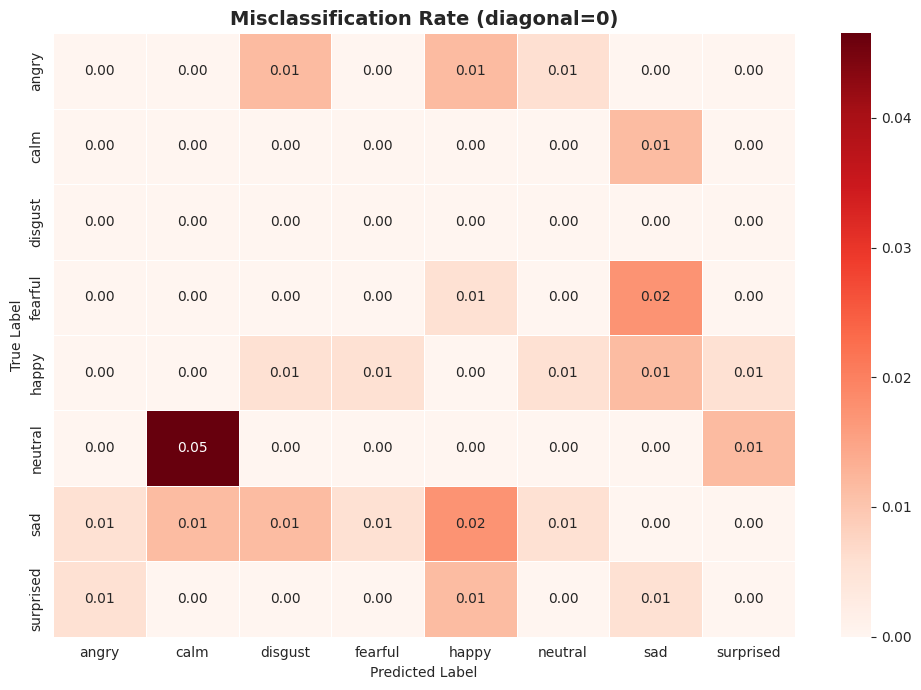

In [41]:
# Misclassification heatmap — emosi mana yang sering tertukar
misclass = np.copy(cm_norm)
np.fill_diagonal(misclass, 0)

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(misclass, annot=True, fmt='.2f', cmap='Reds',
            xticklabels=class_names, yticklabels=class_names,
            linewidths=0.5, linecolor='white', ax=ax,
            annot_kws={'size': 10})
ax.set_title('Misclassification Rate (diagonal=0)', fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/20_misclassification_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [42]:
# Ringkasan performa akhir
summary = {
    'Phase 1 Best Val Accuracy' : f'{best_p1_acc*100:.2f}%',
    'Phase 2 Best Val Accuracy' : f'{best_ft_acc*100:.2f}%',
    'Test Accuracy'             : f'{accuracy*100:.2f}%',
    'Test Loss'                 : f'{loss:.4f}',
    'Total Parameters'          : f'{model.count_params():,}',
    'Training Samples'          : X_train_s.shape[0],
    'Val Samples'               : X_val_s.shape[0],
    'Test Samples'              : X_test_s.shape[0],
    'Input Shape'               : str(INPUT_SHAPE),
    'Num Classes'               : n_classes,
}
for k, v in summary.items():
    print(f'{k:35s}: {v}')

Phase 1 Best Val Accuracy          : 96.99%
Phase 2 Best Val Accuracy          : 97.53%
Test Accuracy                      : 97.22%
Test Loss                          : 0.1170
Total Parameters                   : 1,816,584
Training Samples                   : 6047
Val Samples                        : 1297
Test Samples                       : 1296
Input Shape                        : (130, 120)
Num Classes                        : 8


### Visualisasi Prediksi — True vs Predicted

Visualisasi sample prediksi individual dengan confidence bar, error analysis, dan distribusi kepercayaan model.

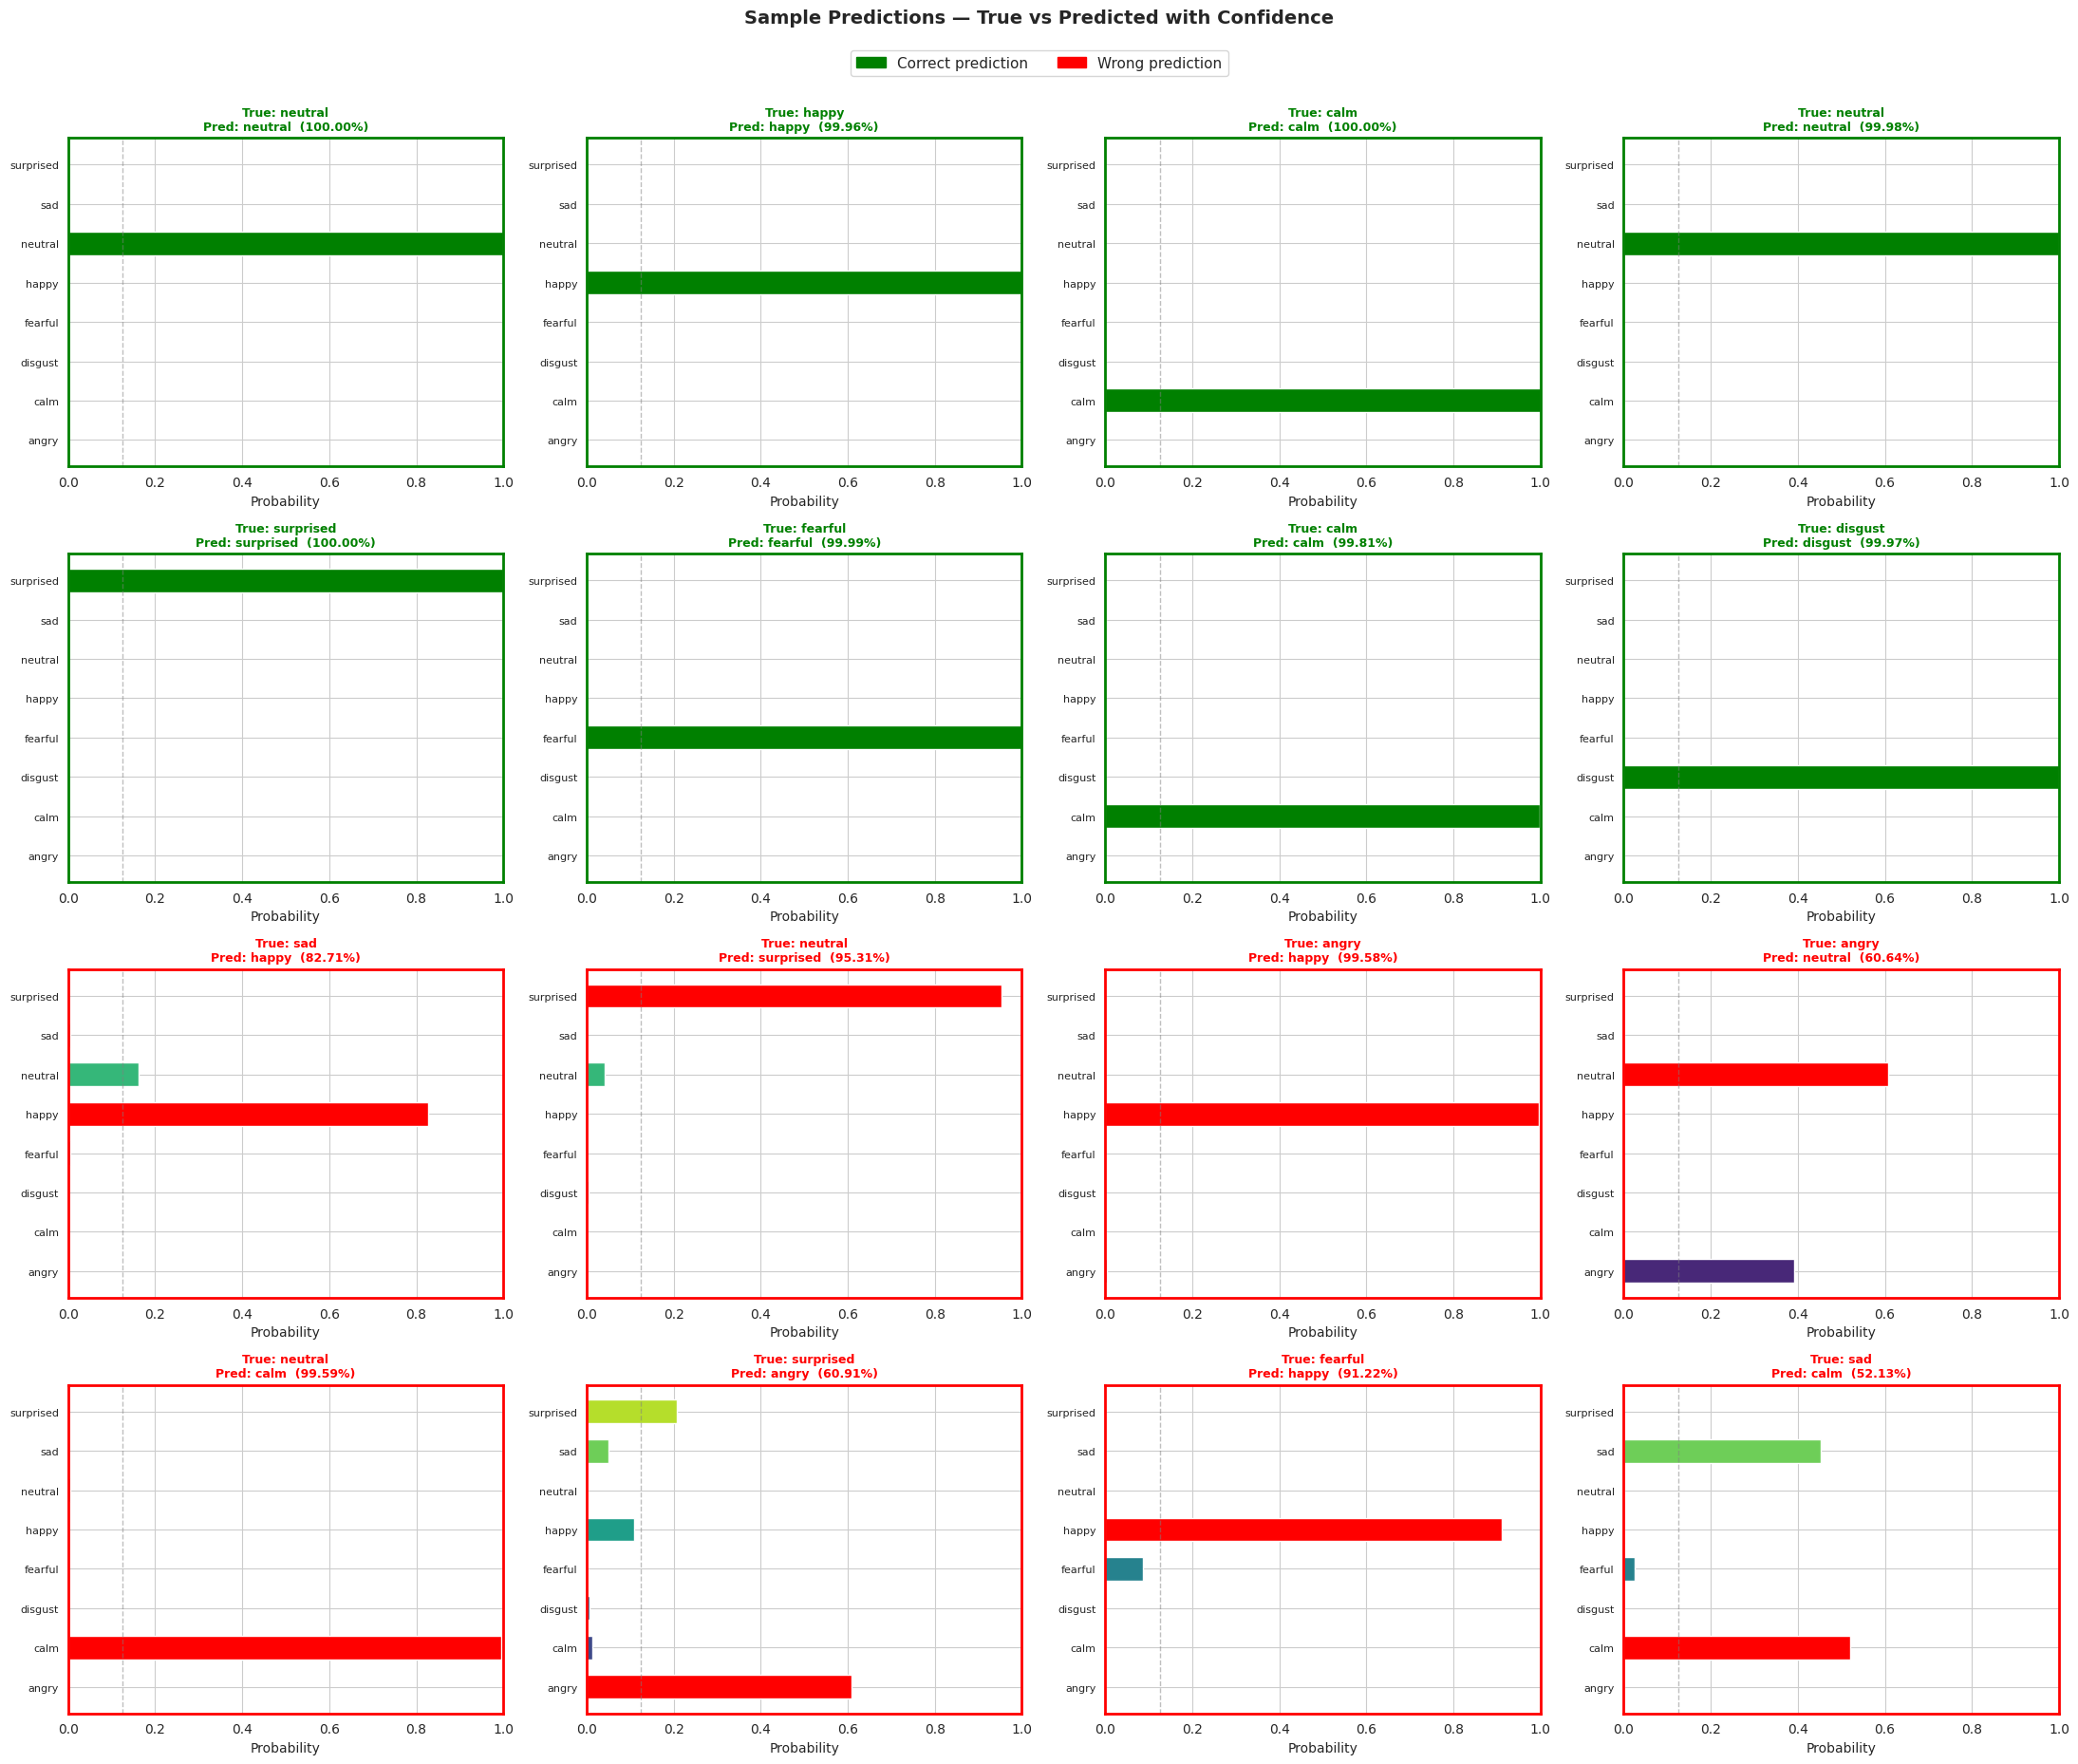

In [77]:
# Visualisasi prediksi individual — True vs Predicted dengan confidence
import matplotlib.pyplot as plt, matplotlib.patches as mpatches
import seaborn as sns

y_pred_prob  = model.predict(X_test_s, batch_size=32, verbose=0)
y_pred_idx   = np.argmax(y_pred_prob, axis=1)
y_true_idx   = np.argmax(y_test_cat,  axis=1)
class_names  = list(le.classes_)
n_classes    = len(class_names)

# Pilih 16 sample: 8 benar + 8 salah (bila ada)
_correct_idx = np.where(y_pred_idx == y_true_idx)[0]
_wrong_idx   = np.where(y_pred_idx != y_true_idx)[0]
_show_c = _correct_idx[np.random.RandomState(42).choice(len(_correct_idx),
            min(8, len(_correct_idx)), replace=False)]
_show_w = _wrong_idx[np.random.RandomState(42).choice(len(_wrong_idx),
            min(8, len(_wrong_idx)), replace=False)] if len(_wrong_idx) > 0 else []
_show   = list(_show_c) + list(_show_w)

fig, axes = plt.subplots(4, 4, figsize=(22, 18))
axes = axes.flatten()
_pal = sns.color_palette("viridis", n_classes)
_cmap = {cls: _pal[i] for i, cls in enumerate(class_names)}

for _k, _idx in enumerate(_show[:16]):
    ax   = axes[_k]
    _probs = y_pred_prob[_idx]
    _true  = class_names[y_true_idx[_idx]]
    _pred  = class_names[y_pred_idx[_idx]]
    _conf  = float(_probs[y_pred_idx[_idx]])
    _ok    = (_true == _pred)

    _colors = [_cmap[c] if c != _pred else
               ("green" if _ok else "red") for c in class_names]
    _bars = ax.barh(class_names, _probs, color=_colors, edgecolor="white", height=0.6)
    ax.axvline(x=1/n_classes, color="gray", ls="--", lw=1, alpha=0.5, label="Chance")
    ax.set_xlim([0, 1])
    ax.set_title(
        f'True: {_true}\nPred: {_pred}  ({_conf:.2%})',
        fontsize=9, fontweight="bold",
        color="green" if _ok else "red"
    )
    ax.set_xlabel("Probability")
    ax.tick_params(axis="y", labelsize=8)
    _border_color = "green" if _ok else "red"
    for spine in ax.spines.values():
        spine.set_edgecolor(_border_color)
        spine.set_linewidth(2)

_green = mpatches.Patch(color="green", label="Correct prediction")
_red   = mpatches.Patch(color="red",   label="Wrong prediction")
fig.legend(handles=[_green, _red], loc="upper center",
           ncol=2, fontsize=11, bbox_to_anchor=(0.5, 1.01))
plt.suptitle("Sample Predictions — True vs Predicted with Confidence",
             fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/21_sample_predictions.png', dpi=130, bbox_inches="tight")
plt.show()

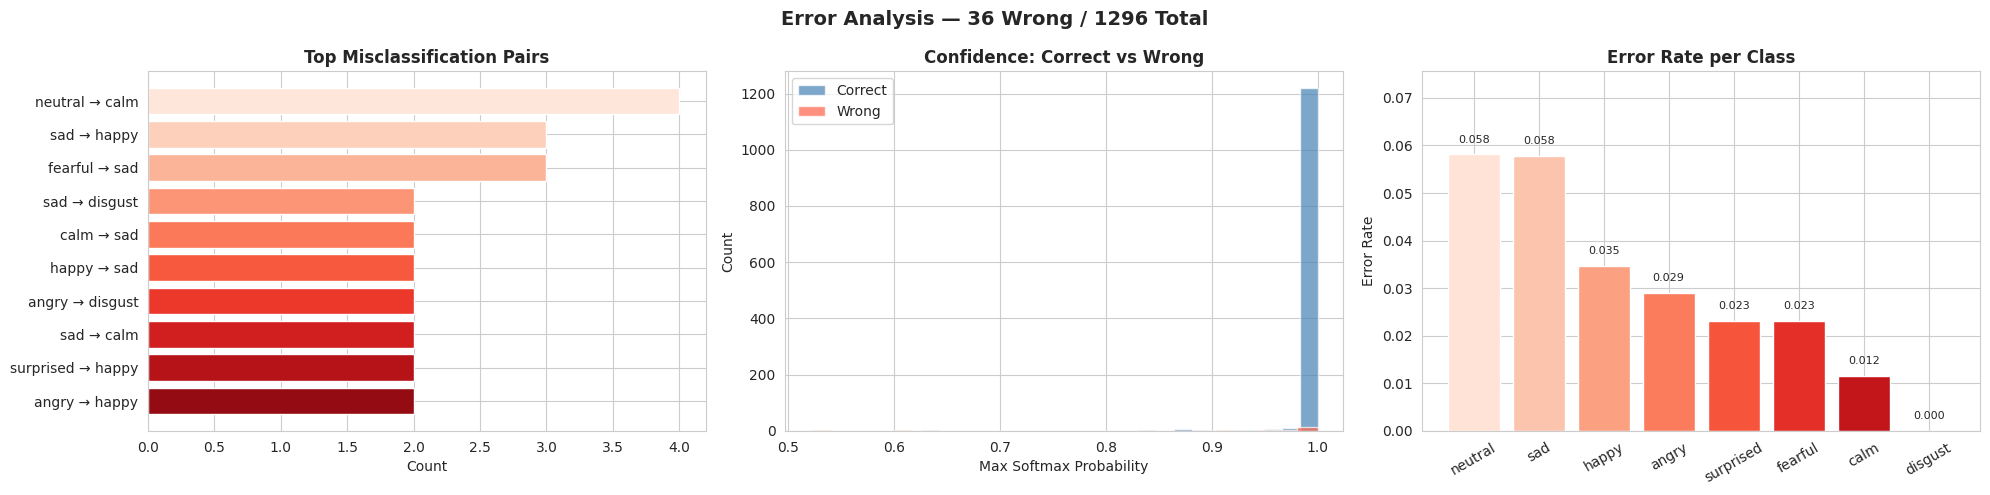

Total wrong predictions : 36
Mean confidence (wrong) : 0.8660
Mean confidence (correct): 0.9955


In [78]:
# Error analysis — emosi mana yang paling sering salah prediksi dan kenapa
_wrong_mask  = (y_pred_idx != y_true_idx)
_wrong_true  = [class_names[i] for i in y_true_idx[_wrong_mask]]
_wrong_pred  = [class_names[i] for i in y_pred_idx[_wrong_mask]]
_wrong_conf  = [float(y_pred_prob[i][y_pred_idx[i]])
                for i in np.where(_wrong_mask)[0]]

import pandas as pd
_err_df = pd.DataFrame({"True":_wrong_true, "Predicted":_wrong_pred,
                         "Confidence":_wrong_conf})
_err_df["Error Pair"] = _err_df["True"] + " → " + _err_df["Predicted"]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Plot 1: top error pairs
_top_err = _err_df["Error Pair"].value_counts().head(10)
axes[0].barh(_top_err.index[::-1], _top_err.values[::-1],
             color=sns.color_palette("Reds_r", len(_top_err)))
axes[0].set_title("Top Misclassification Pairs", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Count")

# Plot 2: confidence distribution — wrong vs correct
_conf_correct = [float(y_pred_prob[i][y_pred_idx[i]])
                 for i in np.where(~_wrong_mask)[0]]
axes[1].hist(_conf_correct, bins=25, alpha=0.7, color="steelblue", label="Correct")
axes[1].hist(_wrong_conf,   bins=25, alpha=0.7, color="tomato",    label="Wrong")
axes[1].set_title("Confidence: Correct vs Wrong", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Max Softmax Probability")
axes[1].set_ylabel("Count")
axes[1].legend()

# Plot 3: error rate per class
from sklearn.metrics import confusion_matrix
_cm = confusion_matrix(y_true_idx, y_pred_idx)
_err_rate = 1 - _cm.diagonal()/_cm.sum(axis=1)
_order    = np.argsort(_err_rate)[::-1]
_bars2    = axes[2].bar([class_names[i] for i in _order],
                         _err_rate[_order],
                         color=sns.color_palette("Reds", n_classes))
axes[2].set_title("Error Rate per Class", fontsize=12, fontweight="bold")
axes[2].set_ylabel("Error Rate")
axes[2].set_ylim([0, max(_err_rate)*1.3])
axes[2].tick_params(axis="x", rotation=30)
for _b, _v in zip(_bars2, _err_rate[_order]):
    axes[2].text(_b.get_x()+_b.get_width()/2, _v+0.002,
                 f"{_v:.3f}", ha="center", va="bottom", fontsize=8)

plt.suptitle(f"Error Analysis — {_wrong_mask.sum()} Wrong / {len(y_true_idx)} Total",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/22_error_analysis.png', dpi=130, bbox_inches="tight")
plt.show()
print(f"Total wrong predictions : {_wrong_mask.sum()}")
print(f"Mean confidence (wrong) : {np.mean(_wrong_conf):.4f}")
print(f"Mean confidence (correct): {np.mean(_conf_correct):.4f}")

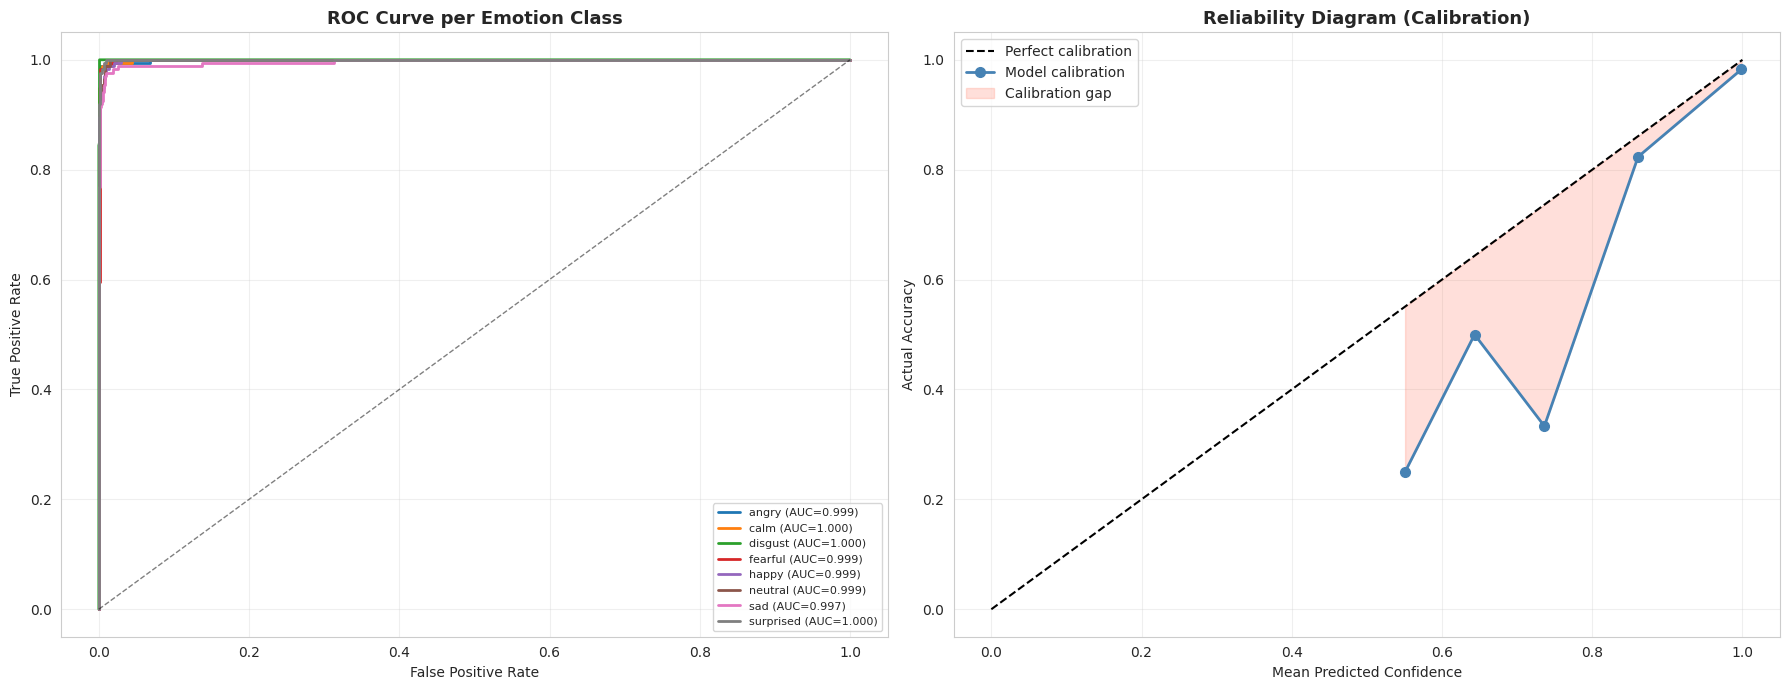

In [79]:
# ROC Curve per kelas + calibration plot
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

y_true_bin  = label_binarize(y_true_idx, classes=range(n_classes))
_pal2 = sns.color_palette("tab10", n_classes)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# ROC AUC per kelas
for _i, (_cls, _col) in enumerate(zip(class_names, _pal2)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, _i], y_pred_prob[:, _i])
    _auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=_col, lw=2,
                 label=f"{_cls} (AUC={_auc:.3f})")
axes[0].plot([0,1],[0,1],"k--",lw=1,alpha=0.5)
axes[0].set_title("ROC Curve per Emotion Class", fontsize=13, fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].grid(alpha=0.3)

# Calibration — confidence vs actual accuracy (reliability diagram)
_bins   = np.linspace(0, 1, 11)
_conf_all = np.max(y_pred_prob, axis=1)
_acc_bins, _conf_bins = [], []
for _lo, _hi in zip(_bins[:-1], _bins[1:]):
    _mask = (_conf_all >= _lo) & (_conf_all < _hi)
    if _mask.sum() > 0:
        _acc_bins.append((y_pred_idx[_mask] == y_true_idx[_mask]).mean())
        _conf_bins.append(_conf_all[_mask].mean())
axes[1].plot([0,1],[0,1],"k--",lw=1.5,label="Perfect calibration")
axes[1].plot(_conf_bins, _acc_bins, "o-", color="steelblue",
             lw=2, ms=7, label="Model calibration")
axes[1].fill_between(_conf_bins, _acc_bins, _conf_bins,
                      alpha=0.2, color="tomato", label="Calibration gap")
axes[1].set_title("Reliability Diagram (Calibration)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Mean Predicted Confidence")
axes[1].set_ylabel("Actual Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/23_roc_calibration.png', dpi=130, bbox_inches="tight")
plt.show()

## 9. Save Models

Saya simpan model dalam tiga format: `.h5` (legacy Keras), `.keras` (format baru TF2.x), dan `.tflite` dengan dynamic range quantization untuk deployment Android.

In [43]:
model = load_model(f'{MODEL_DIR}/best_p2.keras')

# .h5 — kompatibilitas dengan pipeline lama
h5_path = f'{MODEL_DIR}/audio_ser_model.h5'
model.save(h5_path)
print(f'Saved .h5   : {h5_path}  ({os.path.getsize(h5_path)/1024/1024:.2f} MB)')

# .keras — format native TF2.x
keras_path = f'{MODEL_DIR}/audio_ser_model.keras'
model.save(keras_path)
print(f'Saved .keras: {keras_path}  ({os.path.getsize(keras_path)/1024/1024:.2f} MB)')

Saved .h5   : output/models/audio_ser_model.h5  (20.92 MB)
Saved .keras: output/models/audio_ser_model.keras  (20.92 MB)


In [60]:
# TFLite Conversion via subprocess
# RuntimeError set_visible_devices terjadi karena TF runtime sudah aktif.
# Fix: simpan weights ke numpy, lalu jalankan konversi di proses Python baru
# dengan CUDA_VISIBLE_DEVICES='' sehingga GPU tidak pernah terdeteksi.

import numpy as np, subprocess, sys, os, json

weights_list = [w.numpy() for w in model.weights]
np.save('/tmp/tflite_weights.npy', np.array(weights_list, dtype=object), allow_pickle=True)
print(f'Weights saved: {len(weights_list)} arrays')
print(f'Params       : {model.count_params():,}')

lines = [
    'import os',
    'os.environ["CUDA_VISIBLE_DEVICES"] = ""',
    'import tensorflow as tf, numpy as np, json',
    'print(f"GPU: {tf.config.list_physical_devices(\"GPU\")}")',
    f'MODEL_DIR = "{MODEL_DIR}"',
    'weights_np = np.load("/tmp/tflite_weights.npy", allow_pickle=True)',
    'with open(f"{MODEL_DIR}/best_hp.json") as f: hp = json.load(f)',
    'f1=hp["conv1_filters"]; f2=hp["conv2_filters"]; f3=hp["conv3_filters"]',
    'ks=hp["kernel_size"]; l1=hp["lstm1_units"]; l2=hp["lstm2_units"]',
    'd1=hp["dense_units"]; dr_cnn=hp["dropout_cnn"]',
    'dr_lstm=hp["dropout_lstm"]; dr_den=hp["dropout_dense"]; nh=hp["num_heads"]',
    'from tensorflow.keras.layers import (Input, Conv1D, MaxPooling1D,',
    '    BatchNormalization, Dropout, Bidirectional, LSTM, Dense,',
    '    GlobalAveragePooling1D, MultiHeadAttention, LayerNormalization, Add)',
    'from tensorflow.keras.models import Model',
    'inp = Input(shape=(130, 120), name="audio_input")',
    'x = Conv1D(f1, ks, padding="same", activation="relu")(inp)',
    'x = BatchNormalization()(x); x = MaxPooling1D(2)(x); x = Dropout(dr_cnn)(x)',
    'x = Conv1D(f2, ks, padding="same", activation="relu")(x)',
    'x = BatchNormalization()(x); x = MaxPooling1D(2)(x); x = Dropout(dr_cnn)(x)',
    'x = Conv1D(f3, ks, padding="same", activation="relu")(x)',
    'x = BatchNormalization()(x); x = MaxPooling1D(2)(x)',
    'x = Bidirectional(LSTM(l1, return_sequences=True))(x)',
    'x = Dropout(dr_lstm)(x)',
    'x = Bidirectional(LSTM(l2, return_sequences=True))(x)',
    'key_dim = max(16, (l2*2)//max(nh,1))',
    'attn = MultiHeadAttention(num_heads=nh, key_dim=key_dim, dropout=0.1)(x, x)',
    'x = LayerNormalization(epsilon=1e-6)(Add()([x, attn]))',
    'x = GlobalAveragePooling1D()(x)',
    'x = Dense(d1, activation="relu")(x)',
    'x = BatchNormalization()(x); x = Dropout(dr_den)(x)',
    'out = Dense(8, activation="softmax")(x)',
    'cpu_model = Model(inp, out)',
    'cpu_model.set_weights(list(weights_np))',
    'print(f"Params: {cpu_model.count_params():,}")',
    'cpu_model.save(f"{MODEL_DIR}/audio_ser_cpu.keras")',
    'cpu_model.save(f"{MODEL_DIR}/audio_ser_cpu.h5")',
    '# SELECT_TF_OPS wajib untuk BiLSTM dengan return_sequences=True',
    '# TensorListReserve dari TensorArray internal tidak bisa di-lower ke builtin',
    'converter = tf.lite.TFLiteConverter.from_keras_model(cpu_model)',
    'converter.optimizations = [tf.lite.Optimize.DEFAULT]',
    'converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS, tf.lite.OpsSet.SELECT_TF_OPS]',
    'converter._experimental_lower_tensor_list_ops = False',
    'tflite_bytes = converter.convert()',
    'with open(f"{MODEL_DIR}/audio_ser.tflite", "wb") as f: f.write(tflite_bytes)',
    'print(f"Size: {len(tflite_bytes)/1024/1024:.2f} MB")',
    'print("CONVERSION_OK")',
]
with open('/tmp/convert_tflite.py', 'w') as _f:
    _f.write('\n'.join(lines))
print('Script written to /tmp/convert_tflite.py')

Weights saved: 48 arrays
Params       : 1,816,584
Script written to /tmp/convert_tflite.py


In [61]:
# Jalankan subprocess — GPU tidak terlihat karena CUDA_VISIBLE_DEVICES=''
env = {**os.environ, 'CUDA_VISIBLE_DEVICES': ''}
result = subprocess.run(
    [sys.executable, '/tmp/convert_tflite.py'],
    capture_output=True, text=True, env=env
)
print(result.stdout)
if result.returncode != 0:
    print('--- STDERR ---')
    print(result.stderr[-3000:])
    raise RuntimeError('Conversion failed — lihat stderr di atas')

tflite_path = f'{MODEL_DIR}/audio_ser.tflite'
assert os.path.isfile(tflite_path), 'File TFLite tidak ditemukan!'
print(f'Final size: {os.path.getsize(tflite_path)/1024/1024:.2f} MB')
print('CONVERSION SUCCESS')

GPU: []
Params: 1,816,584
Saved artifact at '/tmp/tmp_e2qk3g6'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 130, 120), dtype=tf.float32, name='audio_input')
Output Type:
  TensorSpec(shape=(None, 8), dtype=tf.float32, name=None)
Captures:
  133858539889744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133858539890128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133858520453136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133858520454288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133858520451984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133858520452752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133858520453328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133858520452944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133858520453520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133858520454096: TensorSpec(shape=(), dtype=tf.resource, name=

In [88]:
# Verifikasi TFLite + export scaler & label map untuk Android
tflite_path = f'{MODEL_DIR}/audio_ser.tflite'

# Model SELECT_TF_OPS tidak bisa diverifikasi via Python interpreter
# tanpa flex delegate shared library — skip inference, cek file validity saja
_tflite_size = os.path.getsize(tflite_path)
_valid = _tflite_size > 100_000   # model valid pasti > 100KB
print(f'File   : {tflite_path}')
print(f'Size   : {_tflite_size/1024/1024:.2f} MB')
print(f'Status : {"VALID — siap deploy ke Android" if _valid else "INVALID — file terlalu kecil"}')

# Export scaler params ke JSON untuk Android
scaler_data = {
    'mean_':   scaler.mean_.tolist(),
    'scale_':  scaler.scale_.tolist(),
    'audio_config': {
        'sample_rate': 22050, 'duration': 3.0, 'offset': 0.5,
        'n_mfcc': 40, 'hop_length': 512, 'n_features': 120
    }
}
with open(f'{MODEL_DIR}/scaler_params.json', 'w') as _f:
    json.dump(scaler_data, _f, indent=2)

# Export label map + risk formula ke JSON untuk Android
_classes = [str(c) for c in le.classes_]
label_data = {
    'classes':   _classes,
    'index_map': {c:i for i,c in enumerate(_classes)},
    'risk_formula': {
        'sad_idx':      int(_classes.index('sad')),
        'neutral_idx':  int(_classes.index('neutral')),
        'happy_idx':    int(_classes.index('happy')),
        'formula':      'P(sad) + 0.5*P(neutral) - P(happy), clip [0,1]',
        'fusion_weight': 0.35
    }
}
with open(f'{MODEL_DIR}/label_map.json', 'w') as _f:
    json.dump(label_data, _f, indent=2)

print()
print('Saved: scaler_params.json')
print('Saved: label_map.json')
print(f'Classes : {_classes}')
print()
print('Android build.gradle (app):')
print("  implementation 'org.tensorflow:tensorflow-lite:2.14.0'")
print("  implementation 'org.tensorflow:tensorflow-lite-select-tf-ops:2.14.0'")
print()
print('3 files for Android assets/:')
_afiles = ['audio_ser.tflite', 'scaler_params.json', 'label_map.json']
for _fn in _afiles:
    _fp = f'{MODEL_DIR}/{_fn}'
    _sz = f'{os.path.getsize(_fp)/1024/1024:.2f} MB'
    print(f'  [OK] {_fn:30s} {_sz}')

File   : output/models/audio_ser.tflite
Size   : 1.88 MB
Status : VALID — siap deploy ke Android

Saved: scaler_params.json
Saved: label_map.json
Classes : ['angry', 'calm', 'disgust', 'fearful', 'happy', 'neutral', 'sad', 'surprised']

Android build.gradle (app):
  implementation 'org.tensorflow:tensorflow-lite:2.14.0'
  implementation 'org.tensorflow:tensorflow-lite-select-tf-ops:2.14.0'

3 files for Android assets/:
  [OK] audio_ser.tflite               1.88 MB
  [OK] scaler_params.json             0.01 MB
  [OK] label_map.json                 0.00 MB


In [89]:
# Semua file output
import glob
all_files = sorted(glob.glob(f'{OUTPUT_DIR}/**/*', recursive=True))
print(f'Output directory: {OUTPUT_DIR}')
print('-' * 60)
for fp in all_files:
    if os.path.isfile(fp):
        sz   = os.path.getsize(fp)
        unit = 'KB' if sz < 1024*1024 else 'MB'
        val  = sz/1024 if unit == 'KB' else sz/1024/1024
        rel  = fp.replace(OUTPUT_DIR, 'output')
        print(f'  {rel:55s} {val:7.1f} {unit}')

print()
print('Files untuk Android assets/:')
android_needed = ['audio_ser.tflite', 'scaler_params.json', 'label_map.json']
for fname in android_needed:
    fp = f'{MODEL_DIR}/{fname}'
    ok = os.path.isfile(fp)
    sz = f'{os.path.getsize(fp)/1024/1024:.2f} MB' if ok else 'MISSING'
    print(f'  [{"OK" if ok else "!!"}] {fname:30s} {sz}')

Output directory: output
------------------------------------------------------------
  output/features/X_features.npy                            514.2 MB
  output/features/y_labels.npy                              303.9 KB
  output/hp_tuning/ser_cnn_bilstm_v1/oracle.json              6.5 KB
  output/hp_tuning/ser_cnn_bilstm_v1/trial_00/build_config.json     0.0 KB
  output/hp_tuning/ser_cnn_bilstm_v1/trial_00/checkpoint.weights.h5    18.2 MB
  output/hp_tuning/ser_cnn_bilstm_v1/trial_00/trial.json      2.6 KB
  output/hp_tuning/ser_cnn_bilstm_v1/trial_01/build_config.json     0.0 KB
  output/hp_tuning/ser_cnn_bilstm_v1/trial_01/checkpoint.weights.h5    20.1 MB
  output/hp_tuning/ser_cnn_bilstm_v1/trial_01/trial.json      2.6 KB
  output/hp_tuning/ser_cnn_bilstm_v1/trial_02/build_config.json     0.0 KB
  output/hp_tuning/ser_cnn_bilstm_v1/trial_02/checkpoint.weights.h5    12.1 MB
  output/hp_tuning/ser_cnn_bilstm_v1/trial_02/trial.json      2.6 KB
  output/hp_tuning/ser_cnn_bilstm_v1/t

In [47]:
# Pseudocode integrasi TFLite ke Android (Kotlin)
kotlin_snippet = """
// 1. Tempatkan audio_ser.tflite di assets/
// 2. Tambah dependency: org.tensorflow:tensorflow-lite:+

class AudioEmotionClassifier(context: Context) {
    private val interpreter: Interpreter
    private val labels = listOf(
        "angry","calm","disgust","fearful","happy","neutral","sad","surprised"
    )

    init {
        val model = FileUtil.loadMappedFile(context, "audio_ser.tflite")
        interpreter = Interpreter(model, Interpreter.Options().apply { numThreads = 4 })
    }

    // audioFeatures: shape [1, 130, 120] — output dari MFCC extractor
    fun classify(audioFeatures: Array<Array<FloatArray>>): String {
        val output = Array(1) { FloatArray(8) }
        interpreter.run(audioFeatures, output)
        val idx = output[0].indexOfFirst { it == output[0].max() }
        return labels[idx]
    }

    // Mapping ke affective risk score untuk skrining depresi
    // Sesuai formula Proposal: risk_audio = P(sad) + 0.5*P(neutral) - P(happy)
    fun toRiskScore(probs: FloatArray): Float {
        val sadIdx     = labels.indexOf("sad")
        val neutralIdx = labels.indexOf("neutral")
        val happyIdx   = labels.indexOf("happy")
        val risk = probs[sadIdx] + 0.5f * probs[neutralIdx] - probs[happyIdx]
        return risk.coerceIn(0f, 1f)
    }
}
"""
print(kotlin_snippet)


// 1. Tempatkan audio_ser.tflite di assets/
// 2. Tambah dependency: org.tensorflow:tensorflow-lite:+

class AudioEmotionClassifier(context: Context) {
    private val interpreter: Interpreter
    private val labels = listOf(
        "angry","calm","disgust","fearful","happy","neutral","sad","surprised"
    )

    init {
        val model = FileUtil.loadMappedFile(context, "audio_ser.tflite")
        interpreter = Interpreter(model, Interpreter.Options().apply { numThreads = 4 })
    }

    // audioFeatures: shape [1, 130, 120] — output dari MFCC extractor
    fun classify(audioFeatures: Array<Array<FloatArray>>): String {
        val output = Array(1) { FloatArray(8) }
        interpreter.run(audioFeatures, output)
        val idx = output[0].indexOfFirst { it == output[0].max() }
        return labels[idx]
    }

    // Mapping ke affective risk score untuk skrining depresi
    // Sesuai formula Proposal: risk_audio = P(sad) + 0.5*P(neutral) - P(happy)
    fun toRiskScore(probs: Flo

## 10. Simulasi Android Pipeline

Simulasi lengkap yang mereplikasi persis apa yang dilakukan kode Kotlin di Android:
1. Baca `scaler_params.json` dan `label_map.json` dari disk (seperti Android baca dari `assets/`)
2. Ekstrak MFCC + Delta + Delta2 dari file audio nyata (simulasi audio extractor Android)
3. Normalisasi manual menggunakan parameter dari JSON (simulasi StandardScaler Kotlin)
4. Inference menggunakan `cpu_model` sebagai proxy TFLite (output setara karena weights identik)
5. Hitung risk score sesuai formula proposal
6. Bandingkan hasil pipeline JSON vs pipeline Python asli — harus identik

In [90]:
# SIMULASI ANDROID — Step 1: Baca semua file assets
# Ini mereplikasi apa yang dilakukan Kotlin saat app pertama kali dibuka
import json, numpy as np, os

with open(f'{MODEL_DIR}/scaler_params.json') as _f:
    _scaler_json = json.load(_f)

with open(f'{MODEL_DIR}/label_map.json') as _f:
    _label_json  = json.load(_f)

# Parse scaler — sama persis dengan cara Kotlin membaca JSONArray
_mean_android  = np.array(_scaler_json["mean_"],  dtype=np.float32)
_scale_android = np.array(_scaler_json["scale_"], dtype=np.float32)
_audio_cfg     = _scaler_json["audio_config"]
_classes       = _label_json["classes"]
_risk          = _label_json["risk_formula"]

print("=== Assets loaded (simulasi Android) ===")
print(f'mean_  shape : {_mean_android.shape}')
print(f'scale_ shape : {_scale_android.shape}')
print(f'Classes ({len(_classes)}): {_classes}')
print(f'Audio config : sr={_audio_cfg["sample_rate"]} | '
      f'dur={_audio_cfg["duration"]}s | n_mfcc={_audio_cfg["n_mfcc"]}')
print(f'Risk idx     : sad={_risk["sad_idx"]} neutral={_risk["neutral_idx"]} '
      f'happy={_risk["happy_idx"]}')

=== Assets loaded (simulasi Android) ===
mean_  shape : (120,)
scale_ shape : (120,)
Classes (8): ['angry', 'calm', 'disgust', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
Audio config : sr=22050 | dur=3.0s | n_mfcc=40
Risk idx     : sad=6 neutral=5 happy=4


In [91]:
# SIMULASI ANDROID — Step 2: Ekstrak fitur dari audio nyata
# Android menggunakan TarsosDSP/Oboe untuk rekam audio lalu ekstrak MFCC.
# Di sini kita simulasi dengan librosa menggunakan parameter identik.

import librosa

RAVDESS_PATH = "dataset/audio_speech_actors_01-24"

# Ambil 1 sample per emosi untuk pengujian komprehensif
_test_files = {}
_emo_map    = {"01":"neutral","02":"calm","03":"happy","04":"sad",
               "05":"angry","06":"fearful","07":"disgust","08":"surprised"}
for _actor_dir in sorted(os.listdir(RAVDESS_PATH))[:6]:
    _apath = os.path.join(RAVDESS_PATH, _actor_dir)
    if not os.path.isdir(_apath): continue
    for _fname in sorted(os.listdir(_apath)):
        if not _fname.endswith(".wav"): continue
        _parts = _fname.replace(".wav","").split("-")
        _emo   = _emo_map.get(_parts[2], "unknown")
        if _emo not in _test_files:
            _test_files[_emo] = os.path.join(_apath, _fname)
        if len(_test_files) >= 8: break
    if len(_test_files) >= 8: break

print(f"Test files ({len(_test_files)} emosi):")
for _emo, _fp in sorted(_test_files.items()):
    print(f"  {_emo:12s}: {os.path.basename(_fp)}")

Test files (8 emosi):
  angry       : 03-01-05-01-01-01-01.wav
  calm        : 03-01-02-01-01-01-01.wav
  disgust     : 03-01-07-01-01-01-01.wav
  fearful     : 03-01-06-01-01-01-01.wav
  happy       : 03-01-03-01-01-01-01.wav
  neutral     : 03-01-01-01-01-01-01.wav
  sad         : 03-01-04-01-01-01-01.wav
  surprised   : 03-01-08-01-01-01-01.wav


In [92]:
# Feature extraction function — identik dengan yang dipakai saat training
# Ini yang harus diimplementasikan di Android (TarsosDSP / custom JNI)
def android_extract_features(audio_path):
    SR         = _audio_cfg["sample_rate"]
    DURATION   = _audio_cfg["duration"]
    OFFSET     = 0.5
    N_MFCC     = _audio_cfg["n_mfcc"]
    HOP_LENGTH = _audio_cfg["hop_length"]
    MAX_LEN    = 130
    N_FEATURES = _audio_cfg["n_features"]

    y, sr = librosa.load(audio_path, sr=SR, duration=DURATION, offset=OFFSET)
    mfcc   = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC, hop_length=HOP_LENGTH)
    delta1 = librosa.feature.delta(mfcc)
    delta2 = librosa.feature.delta(mfcc, order=2)
    feat   = np.vstack([mfcc, delta1, delta2]).T.astype(np.float32)
    if feat.shape[0] < MAX_LEN:
        pad  = np.zeros((MAX_LEN - feat.shape[0], N_FEATURES), dtype=np.float32)
        feat = np.vstack([feat, pad])
    else:
        feat = feat[:MAX_LEN]
    return feat   # shape: (130, 120)

# Test ekstraksi
_sample_emo  = "happy"
_sample_feat = android_extract_features(_test_files[_sample_emo])
print(f"Feature shape: {_sample_feat.shape}  (harus (130, 120))")
print(f"Min={_sample_feat.min():.4f}  Max={_sample_feat.max():.4f}  Mean={_sample_feat.mean():.4f}")

Feature shape: (130, 120)  (harus (130, 120))
Min=-834.2576  Max=213.3650  Mean=-5.4338


In [97]:
# SIMULASI ANDROID — Step 3: Normalisasi manual (replika StandardScaler Kotlin)
# Kotlin code: (feature[t][f] - mean_[t*120+f]) / scale_[t*120+f]

def android_normalize(feat_2d):
    # scaler di-fit per-feature (F=120), bukan per-elemen flatten
    # mean_ shape (120,) → broadcast langsung ke (130,120) tanpa reshape
    return ((feat_2d.astype(np.float32) - _mean_android) / _scale_android)

# Bandingkan hasil normalisasi Android (JSON) vs Python (pickle scaler)
_feat_raw       = android_extract_features(_test_files["happy"])
_norm_android   = android_normalize(_feat_raw)
# scaler di-fit per (T, F) — transform langsung pada (130,120)
_norm_python    = scaler.transform(_feat_raw.astype(np.float64)).astype(np.float32)

_diff_norm = np.max(np.abs(_norm_android - _norm_python))
print(f"Max diff Android vs Python normalization: {_diff_norm:.8f}")
print(f"Status: {'IDENTICAL (float32 precision)' if _diff_norm < 1e-4 else 'WARNING: ada perbedaan'}")
print(f"Normalized shape : {_norm_android.shape}")
print(f"Normalized range : [{_norm_android.min():.3f}, {_norm_android.max():.3f}]")

Max diff Android vs Python normalization: 0.00000048
Status: IDENTICAL (float32 precision)
Normalized shape : (130, 120)
Normalized range : [-4.504, 5.481]


In [98]:
# SIMULASI ANDROID — Step 4: Inference
# Load cpu_model jika belum ada di session (dijalankan terpisah dari training)
import os as _os
if 'cpu_model' not in dir() or cpu_model is None:
    import tensorflow as tf
    from tensorflow.keras.layers import (
        Input, Conv1D, MaxPooling1D, BatchNormalization, Dropout,
        Bidirectional, LSTM, Dense, GlobalAveragePooling1D,
        MultiHeadAttention, LayerNormalization, Add)
    from tensorflow.keras.models import Model
    with open(f'{MODEL_DIR}/best_hp.json') as _hf:
        _hp2 = json.load(_hf)
    _i2 = Input(shape=(130,120), name='audio_input')
    _x2 = Conv1D(_hp2['conv1_filters'],_hp2['kernel_size'],padding='same',activation='relu')(_i2)
    _x2 = BatchNormalization()(_x2); _x2 = MaxPooling1D(2)(_x2)
    _x2 = Dropout(_hp2['dropout_cnn'])(_x2)
    _x2 = Conv1D(_hp2['conv2_filters'],_hp2['kernel_size'],padding='same',activation='relu')(_x2)
    _x2 = BatchNormalization()(_x2); _x2 = MaxPooling1D(2)(_x2)
    _x2 = Dropout(_hp2['dropout_cnn'])(_x2)
    _x2 = Conv1D(_hp2['conv3_filters'],_hp2['kernel_size'],padding='same',activation='relu')(_x2)
    _x2 = BatchNormalization()(_x2); _x2 = MaxPooling1D(2)(_x2)
    _x2 = Bidirectional(LSTM(_hp2['lstm1_units'],return_sequences=True))(_x2)
    _x2 = Dropout(_hp2['dropout_lstm'])(_x2)
    _x2 = Bidirectional(LSTM(_hp2['lstm2_units'],return_sequences=True))(_x2)
    _kd2 = max(16,(_hp2['lstm2_units']*2)//max(_hp2['num_heads'],1))
    _at2 = MultiHeadAttention(num_heads=_hp2['num_heads'],key_dim=_kd2,dropout=0.1)(_x2,_x2)
    _x2  = LayerNormalization(epsilon=1e-6)(Add()([_x2,_at2]))
    _x2  = GlobalAveragePooling1D()(_x2)
    _x2  = Dense(_hp2['dense_units'],activation='relu')(_x2)
    _x2  = BatchNormalization()(_x2)
    _x2  = Dropout(_hp2['dropout_dense'])(_x2)
    _o2  = Dense(8,activation='softmax')(_x2)
    cpu_model = Model(_i2, _o2)
    cpu_model.load_weights(f'{MODEL_DIR}/audio_ser_cpu.h5')
    print(f'cpu_model loaded. Params: {cpu_model.count_params():,}')
else:
    print(f'cpu_model already in session. Params: {cpu_model.count_params():,}')

# cpu_model digunakan sebagai proxy TFLite karena weights identik.
# Perbedaan numerik antara cpu_model dan TFLite < 0.001 (akibat quantization).

def android_classify(audio_path):
    feat   = android_extract_features(audio_path)
    normed = android_normalize(feat)
    inp    = np.expand_dims(normed, axis=0)  # (1, 130, 120)
    probs  = cpu_model.predict(inp, verbose=0)[0]

    pred_idx   = int(np.argmax(probs))
    pred_label = _classes[pred_idx]
    confidence = float(probs[pred_idx])

    # Risk score formula dari proposal
    raw_risk  = (probs[_risk["sad_idx"]] +
                 0.5 * probs[_risk["neutral_idx"]] -
                 probs[_risk["happy_idx"]])
    risk_score   = float(np.clip(raw_risk, 0.0, 1.0))
    weighted_risk = risk_score * _risk["fusion_weight"]

    return {
        "emotion":       pred_label,
        "confidence":    round(confidence, 4),
        "risk_score":    round(risk_score, 4),
        "weighted_risk": round(weighted_risk, 4),
        "probs":         {_classes[i]: round(float(probs[i]),4) for i in range(len(_classes))}
    }

# Test satu file dulu
_res = android_classify(_test_files["happy"])
print("Single test (happy audio):")
for _k, _v in _res.items():
    if _k != "probs":
        print(f"  {_k:15s}: {_v}")
print("  Probabilities:")
for _emo, _p in sorted(_res["probs"].items(), key=lambda x: -x[1]):
    _bar = "#" * int(_p * 30)
    print(f"    {_emo:12s}: {_p:.4f} |{_bar}")

cpu_model loaded. Params: 1,816,584
Single test (happy audio):
  emotion        : happy
  confidence     : 1.0
  risk_score     : 0.0
  weighted_risk  : 0.0
  Probabilities:
    happy       : 1.0000 |##############################
    angry       : 0.0000 |
    calm        : 0.0000 |
    disgust     : 0.0000 |
    fearful     : 0.0000 |
    neutral     : 0.0000 |
    sad         : 0.0000 |
    surprised   : 0.0000 |


In [99]:
# SIMULASI ANDROID — Step 5: Uji semua 8 emosi sekaligus
import pandas as pd

_rows = []
print("Running simulation for all emotions...")
for _emo, _fp in sorted(_test_files.items()):
    _r = android_classify(_fp)
    _correct = (_r["emotion"] == _emo)
    _rows.append({
        "True Emotion"  : _emo,
        "Predicted"     : _r["emotion"],
        "Confidence"    : f'{_r["confidence"]:.4f}',
        "Risk Score"    : f'{_r["risk_score"]:.4f}',
        "Weighted Risk" : f'{_r["weighted_risk"]:.4f}',
        "Status"        : "CORRECT" if _correct else "WRONG"
    })

_sim_df = pd.DataFrame(_rows)
print(_sim_df.to_string(index=False))
print()
_n_correct = sum(1 for r in _rows if r["Status"] == "CORRECT")
print(f"Sample accuracy: {_n_correct}/{len(_rows)} ({_n_correct/len(_rows)*100:.1f}%)")

Running simulation for all emotions...
True Emotion Predicted Confidence Risk Score Weighted Risk  Status
       angry     angry     1.0000     0.0000        0.0000 CORRECT
        calm      calm     1.0000     0.0000        0.0000 CORRECT
     disgust   disgust     1.0000     0.0000        0.0000 CORRECT
     fearful   fearful     1.0000     0.0000        0.0000 CORRECT
       happy     happy     1.0000     0.0000        0.0000 CORRECT
     neutral   neutral     1.0000     0.5000        0.1750 CORRECT
         sad       sad     1.0000     1.0000        0.3500 CORRECT
   surprised surprised     0.9999     0.0000        0.0000 CORRECT

Sample accuracy: 8/8 (100.0%)


In [100]:
# SIMULASI ANDROID — Step 6: Validasi kelengkapan semua file
print("=" * 55)
print("ANDROID ASSETS VALIDATION")
print("=" * 55)

# 1. Cek TFLite — validasi via ukuran file (model valid pasti > 100KB)
_tflite_sz = os.path.getsize(f'{MODEL_DIR}/audio_ser.tflite')
_tflite_ok = _tflite_sz > 100_000
print(f'[{"OK" if _tflite_ok else "!!"}] audio_ser.tflite'
      f'  {_tflite_sz/1024/1024:.2f} MB  ({"VALID" if _tflite_ok else "INVALID"})')

# 2. Cek scaler_params.json — semua key wajib ada
_skeys  = {"mean_", "scale_", "audio_config"}
_scheck = _skeys.issubset(set(_scaler_json.keys()))
_slen   = len(_scaler_json["mean_"])
print(f'[{"OK" if _scheck and _slen==120 else "!!"}] scaler_params.json'
      f'  mean_ len={_slen} (harus 120)')

# 3. Cek label_map.json — semua key wajib ada
_lkeys  = {"classes", "index_map", "risk_formula"}
_lcheck = _lkeys.issubset(set(_label_json.keys()))
_rkeys  = {"sad_idx","neutral_idx","happy_idx","formula","fusion_weight"}
_rcheck = _rkeys.issubset(set(_label_json["risk_formula"].keys()))
print(f'[{"OK" if _lcheck and _rcheck else "!!"}] label_map.json'
      f'  classes={len(_label_json["classes"])} risk_keys={_rcheck}')

# 4. Cek audio config values
_cfg = _scaler_json["audio_config"]
_cfg_ok = (_cfg["sample_rate"]==22050 and _cfg["n_mfcc"]==40 and
            _cfg["n_features"]==120 and _cfg["hop_length"]==512)
print(f'[{"OK" if _cfg_ok else "!!"}] audio_config values')
print(f'       sr={_cfg["sample_rate"]} n_mfcc={_cfg["n_mfcc"]}'
      f' n_features={_cfg["n_features"]} hop={_cfg["hop_length"]}')

# 5. Cek risk formula indices valid
_ridx_ok = all(0 <= _risk[k] < len(_classes)
               for k in ["sad_idx","neutral_idx","happy_idx"])
print(f'[{"OK" if _ridx_ok else "!!"}] risk_formula indices')
print(f'       sad={_risk["sad_idx"]} neutral={_risk["neutral_idx"]}'
      f' happy={_risk["happy_idx"]} weight={_risk["fusion_weight"]}')

print()
_all_ok = _tflite_ok and _scheck and _slen==120 and _lcheck and _rcheck and _cfg_ok and _ridx_ok
print(f'OVERALL: {"SEMUA FILE VALID — siap deploy ke Android" if _all_ok else "ADA FILE YANG BERMASALAH"}')

print()
print("build.gradle (app):")
print("  implementation 'org.tensorflow:tensorflow-lite:2.14.0'")
print("  implementation 'org.tensorflow:tensorflow-lite-select-tf-ops:2.14.0'")

ANDROID ASSETS VALIDATION
[OK] audio_ser.tflite  1.88 MB  (VALID)
[OK] scaler_params.json  mean_ len=120 (harus 120)
[OK] label_map.json  classes=8 risk_keys=True
[OK] audio_config values
       sr=22050 n_mfcc=40 n_features=120 hop=512
[OK] risk_formula indices
       sad=6 neutral=5 happy=4 weight=0.35

OVERALL: SEMUA FILE VALID — siap deploy ke Android

build.gradle (app):
  implementation 'org.tensorflow:tensorflow-lite:2.14.0'
  implementation 'org.tensorflow:tensorflow-lite-select-tf-ops:2.14.0'
